# 审计与清洗过程说明

这个 notebook 用通俗的方式解释：数据审计发现了什么问题、清洗规则是什么、阈值为什么这样定。

- **只做解释和展示**：不修改任何数据，不写任何数据文件，也不替代 `src/` 里的清洗管道。
- 每一节按同样的五步写：**问题是什么 → 先看数据 → 规则 → 删除或标记了多少 → 核对**。
- 每条规则的删除数和标记数都在这里**独立重算**（不调用 `src/` 的清洗代码），再用 `assert` 与管道输出
  `data/processed/clean_rule_ledger_daily.parquet`、`clean_report.md` 核对。
- 唯一的例外是研究过滤：它只能通过 `clean.filters.apply_research_filter()` 计算（研究代码不允许自己另写过滤条件），
  notebook 也调用它，并用独立重算的结果核对。

> **原则：面板只删除不是真实观测的数据**——复制出来的曲线（1a）、曲线内残留的旧行（2a、2b）。
> 其余所有真实观测，即使质量可疑（迟到的快照、离到期太近、拟合差、供应商检查不通过），都保留下来并加上标记，
> 由研究阶段通过 `apply_research_filter()` 决定是否使用。
> 原因：`vol_curve_check` 中有 `IV_RV_DIFF` 这样的取值，它按 IV 与 RV 的差距筛选曲线——这正是要研究的 VRP。
> 在面板阶段删掉它们，会在不知不觉中截掉 VRP 的尾部。
- 所有阈值从 `config/clean.yaml` 和 `config/audit.yaml` 读取。

## 准备：导入、字体、路径、配置

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml  # 只用来读 config/*.yaml
from scipy.stats import norm, pearsonr, spearmanr

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

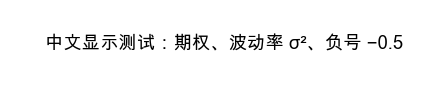

In [2]:
# 中文字体：Arial Unicode MS 同时包含中文、负号 − 和上标 ²
plt.rcParams['font.sans-serif'] = ['Arial Unicode MS', 'PingFang SC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 110

fig, ax = plt.subplots(figsize=(5, 0.8))
ax.text(0.5, 0.5, '中文显示测试：期权、波动率 σ²、负号 −0.5', ha='center', va='center', fontsize=12)
ax.axis('off')
plt.show()

In [3]:
# 项目根目录：notebook 在 notebooks/ 下运行
ROOT = Path.cwd() if (Path.cwd() / 'config').exists() else Path.cwd().parent
RAW_OPT = ROOT / 'data/raw/options_daily/asset=BTC'
RAW_UND = ROOT / 'data/raw/underlyings_daily/asset=BTC'
AUDIT = ROOT / 'data/audit'
PROC = ROOT / 'data/processed'

clean_cfg = yaml.safe_load(open(ROOT / 'config/clean.yaml'))
audit_cfg = yaml.safe_load(open(ROOT / 'config/audit.yaml'))
rules = clean_cfg['rules']

import sys
sys.path.insert(0, str(ROOT / 'src'))
from clean import filters   # 研究过滤的唯一入口
rules

{'lingering_tol_s': 60,
 'max_age_min': 10,
 'min_tenor_days': 1.0,
 'min_r_squared': 0.9,
 'iv_floor': 0.03,
 'iv_floor_tol': 1e-06}

In [4]:
# 常用常数，全部来自配置
YEAR_DAYS = clean_cfg['conventions']['year_days']
SWITCH_TIME = pd.Timestamp(clean_cfg['clock']['switch_time'])
TIER_EDGES_MIN = audit_cfg['snapshot']['freshness_edges_min']
TENOR_EDGES = audit_cfg['expiries']['tenor_buckets_days']
KEYS = ['timestamp', 'expiry']
HOUR = pd.Timedelta('1h')
print('一年天数', YEAR_DAYS, '| 时钟切换', SWITCH_TIME, '| 年龄分档边界（分钟）', TIER_EDGES_MIN)

一年天数 365.25 | 时钟切换 2025-06-28 00:00:00+00:00 | 年龄分档边界（分钟） [10, 60]


In [5]:
# 几个很短的辅助函数
def age_tier(age_min):
    edges = [-np.inf] + TIER_EDGES_MIN + [np.inf]
    labels = [f'<{TIER_EDGES_MIN[0]}分钟', f'{TIER_EDGES_MIN[0]}–{TIER_EDGES_MIN[1]}分钟', f'>{TIER_EDGES_MIN[1]}分钟']
    return pd.cut(age_min, bins=edges, labels=labels, right=False)

def tenor_bucket(days):
    labels = [f'{a}-{b}天' for a, b in zip(TENOR_EDGES[:-1], TENOR_EDGES[1:])]
    return pd.cut(days, bins=TENOR_EDGES, labels=labels, right=False)

LOGM_EDGES = [-np.inf, -1, -0.5, -0.25, -0.1, 0, 0.1, 0.25, 0.5, 1, np.inf]
def logm_bucket(logm):
    return pd.cut(logm, bins=LOGM_EDGES)

In [6]:
# 管道的规则台账：删除规则记录剔除的行数和曲线数，标记规则记录被标记的曲线数
ledger_daily = pd.read_parquet(PROC / 'clean_rule_ledger_daily.parquet')
deleted = ledger_daily[ledger_daily.action == 'delete']
ledger = deleted.groupby('rule', sort=False)[['rows_in', 'rows_removed', 'curves_in', 'curves_removed']].sum().astype(int)
ledger.index = [name[:2] for name in ledger.index]   # 只保留编号 1a、2a、2b
flag_ledger = ledger_daily[ledger_daily.action == 'flag'].groupby('rule', sort=False)[
    ['curves_flagged', 'rows_flagged', 'curves_in']].sum().astype(int)

def flag_count(prefix):
    # 台账中以 prefix 开头的那条标记规则的曲线数
    return int(flag_ledger.loc[[r for r in flag_ledger.index if r.startswith(prefix)][0], 'curves_flagged'])
display(ledger)
flag_ledger

,rows_in,rows_removed,curves_in,curves_removed
1a,6103424,24046,90245,366
2a,6079378,3460,89879,0
2b,6075918,0,89879,0


,curves_flagged,rows_flagged,curves_in
rule,,,
1b_flag_late_snapshot_gt_10min,476,30724,89879
3a_flag_short_tenor_lt_1d,7928,400130,89879
3b_flag_low_r2_lt_0.9,1176,63630,89879
3c_vendor_check=EARLY_EXIT_INSUFFICIENT_STRIKES,1738,86380,89879
3c_vendor_check=FAILED_PIPELINE,9,542,89879
3c_vendor_check=MONEYNESS_DISCREPANCY,6,458,89879
3c_vendor_check=IV_RV_DIFF,441,31546,89879
3c_vendor_check=BAD_BASE_VAL,116,7920,89879
3c_vendor_check=VOL_SPIKE,62,3618,89879


In [7]:
# 读 clean_report.md，并写一个解析其中 markdown 表格的小函数
report_md = (PROC / 'clean_report.md').read_text()

def md_table_after(text, heading):
    block = text.split(heading, 1)[1].split('\n\n', 2)[1]
    lines = [l for l in block.splitlines() if l.startswith('|')]
    header = [h.strip() for h in lines[0].strip('|').split('|')]
    rows = [[c.strip() for c in l.strip('|').split('|')] for l in lines[2:]]
    return pd.DataFrame(rows, columns=header)

### 读入全年期权数据（只读需要的列）

全年约 610 万行。只读后面要用的 13 列，并把文字列转成 category 以节省内存。

In [8]:
OPT_COLUMNS = ['timestamp', 'expiry', 'expiry_label', 'strike', 'option_type', 'raw_timestamp',
               'implied_vol', 'tau_years', 'forward_price', 'delta', 'is_stale',
               'surface_key_type', 'r_squared', 'vol_curve_check']
opt_range = clean_cfg['ranges']['options']
opt_dates = pd.date_range(opt_range['start'], opt_range['end']).strftime('%Y-%m-%d')

frames = []
for d in opt_dates:
    path = RAW_OPT / f'date={d}' / f'options_BTC_{d}_60min.parquet'
    frames.append(pd.read_parquet(path, columns=OPT_COLUMNS))
raw = pd.concat(frames, ignore_index=True)
del frames

In [9]:
for col in ['expiry_label', 'option_type', 'surface_key_type', 'vol_curve_check']:
    raw[col] = raw[col].astype('category')
raw['is_atm'] = raw['surface_key_type'] == 'atm'
raw['logm'] = np.log(raw['strike'] / raw['forward_price'])
raw['curve_id'] = raw.groupby(KEYS, observed=True).ngroup()   # 每条（timestamp, expiry）曲线一个编号
print(f'{len(raw):,} 行，{raw.curve_id.nunique():,} 条曲线，内存 {raw.memory_usage(deep=True).sum() / 1e9:.2f} GB')

6,103,424 行，90,245 条曲线，内存 0.58 GB


## 0. 数据长什么样

**问题是什么。** 先弄清楚每一行代表什么。这份期权数据不是交易所的成交或报价，而是供应商对每个到期日拟合了一条
"波动率曲线"（每个行权价对应一个隐含波动率 IV），再用 **Black-76 公式**把 IV 换算成价格。

- **IV（隐含波动率）**：让期权理论价格等于市场价格的那个波动率，单位是"年化"。
- **Black-76**：给期货/远期上的欧式期权定价的公式，输入是远期价格 F、行权价 K、到期时间 T（年）和 IV。
  这里用的是"无折现"版本，也就是不乘以折现因子。
- **forward（远期价格）**：到期日对应的标的远期价格。

所以价格列不包含额外信息：知道 IV、F、K、T 就能算出来。

### 先看数据：一行样本

In [10]:
sample_day = raw[raw.timestamp.dt.strftime('%Y-%m-%d') == '2025-04-24']
example = sample_day[(sample_day.expiry_label == '16MAY25') & (sample_day.strike == 100000)
                     & (sample_day.option_type == 'call')].iloc[0]
example

timestamp           2025-04-24 21:00:00+00:00
expiry              2025-05-16 08:00:00+00:00
expiry_label                          16MAY25
strike                               100000.0
option_type                              call
raw_timestamp                 1745531998601.0
implied_vol                            0.4476
tau_years                            0.058636
forward_price                    93583.569344
delta                                 0.28854
is_stale                                False
surface_key_type                       strike
r_squared                            0.958459
vol_curve_check                          GOOD
is_atm                                  False
logm                                 0.066315
curve_id                                  103
Name: 0, dtype: object

### 手算一个价格

无折现 Black-76 的看涨期权价格：

$$C = F\,N(d_1) - K\,N(d_2),\qquad d_1 = \frac{\ln(F/K) + \tfrac12\sigma^2 T}{\sigma\sqrt T},\quad d_2 = d_1 - \sigma\sqrt T$$

其中 $N(\cdot)$ 是标准正态分布的累积分布函数。表里没有读价格列（节省内存），这里单独读这一天的 `mid`。

In [11]:
F, K = example.forward_price, example.strike
T, sigma = example.tau_years, example.implied_vol
d1 = (np.log(F / K) + 0.5 * sigma**2 * T) / (sigma * np.sqrt(T))
d2 = d1 - sigma * np.sqrt(T)
price_by_hand = F * norm.cdf(d1) - K * norm.cdf(d2)

day_prices = pd.read_parquet(RAW_OPT / 'date=2025-04-24/options_BTC_2025-04-24_60min.parquet',
                             columns=['timestamp', 'instrument_name', 'mid', 'bid', 'ask'])
row_price = day_prices[(day_prices.timestamp == example.timestamp)
                       & (day_prices.instrument_name == 'BTC-16MAY25-100000-C')].iloc[0]
print(f'手算价格 {price_by_hand:.8f}，表中 mid {row_price.mid:.8f}，bid {row_price.bid:.8f}，ask {row_price.ask:.8f}')
print(f'相对误差 {abs(price_by_hand - row_price.mid) / row_price.mid:.2e}')

手算价格 1733.34211945，表中 mid 1733.34211945，bid 1733.34211945，ask 1733.34211945
相对误差 4.20e-15


In [12]:
# 核对：手算价格与表中价格一致，bid == ask == mid
assert abs(price_by_hand - row_price.mid) / row_price.mid < 1e-8
assert row_price.bid == row_price.ask == row_price.mid

### 同一行权价上，call 和 put 的 IV 相同

In [13]:
one_curve = sample_day[(sample_day.timestamp == example.timestamp) & (sample_day.expiry_label == '16MAY25')
                       & ~sample_day.is_atm]
iv_by_type = one_curve.pivot_table(index='strike', columns='option_type', values='implied_vol', observed=True)
iv_by_type['差值'] = iv_by_type['call'] - iv_by_type['put']
iv_by_type.head(8)

option_type,call,put,差值
strike,,,
75000.0,0.536565,0.536565,0.0
80000.0,0.497459,0.497459,0.0
84000.0,0.465430,0.465430,0.0
85000.0,0.459597,0.459597,0.0
86000.0,0.454558,0.454558,0.0
88000.0,0.446693,0.446693,0.0
89000.0,0.443800,0.443800,0.0
90000.0,0.441557,0.441557,0.0


In [14]:
# 全年检查：同一（timestamp, expiry, strike）上 call IV 与 put IV 的最大差
iv_pairs = raw.pivot_table(index=KEYS + ['strike'], columns='option_type', values='implied_vol',
                           aggfunc='first', observed=True)
max_iv_gap = (iv_pairs['call'] - iv_pairs['put']).abs().max()
print('全年 call/put IV 最大差：', max_iv_gap)
assert max_iv_gap == 0
del iv_pairs

全年 call/put IV 最大差： 0.0


**从结果能看出什么：** 手算价格与表中 mid 的相对误差只有 4e-15，bid、ask、mid 三者完全相同；全年所有行权价上 call 与 put 的 IV 差恰好为 0。所以价格列和 put 都不含额外信息，真正的数据只有每条曲线上的 IV（以及 F、T）。

## 1. 时间戳

**问题是什么。** 数据里有两个时间：

- `timestamp`：小时 **bar 的开始时刻**，比如 10:00 表示 10:00–11:00 这一小时。
- `raw_timestamp`：数据**实际被拍下（快照）的时间**，单位是毫秒。正常情况下在 10:59:5x，也就是这一小时的最后时刻。

关键点是：`raw_timestamp` **不是每小时一个**，而是**每个到期日的曲线各有一个**。同一小时内，不同到期日的快照相差不到一秒。
所以后面判断"新不新鲜"，必须以（timestamp, 到期日）这条曲线为单位，而不是以小时为单位。

### 先看数据：2025-04-24 10:00 这一小时

In [15]:
hour_rows = sample_day[sample_day.timestamp == pd.Timestamp('2025-04-24 10:00', tz='UTC')]
per_expiry = hour_rows.groupby('expiry_label', observed=True).agg(
    行数=('strike', 'size'), raw_timestamp个数=('raw_timestamp', 'nunique'), raw_timestamp=('raw_timestamp', 'max'))
per_expiry['快照时间'] = pd.to_datetime(per_expiry.raw_timestamp, unit='ms', utc=True).dt.strftime('%H:%M:%S.%f').str[:-3]
per_expiry.drop(columns='raw_timestamp')

,行数,raw_timestamp个数,快照时间
expiry_label,,,
25APR25,118,1,10:59:57.846
26APR25,44,1,10:59:57.796
26SEP25,70,1,10:59:58.103
27JUN25,74,1,10:59:57.975
2MAY25,74,1,10:59:58.034
30MAY25,86,1,10:59:58.175
9MAY25,62,1,10:59:57.907


In [16]:
# 全年：每个小时里，曲线快照时间（每条曲线取最新 raw_timestamp）的个数，是否等于到期日个数
raw['curve_obs_ms'] = raw.groupby('curve_id').raw_timestamp.transform('max')
per_hour = raw.groupby('timestamp').agg(n_expiries=('expiry', 'nunique'),
                                        n_curve_snaps=('curve_obs_ms', 'nunique'),
                                        n_raw_ts=('raw_timestamp', 'nunique'))
share_equal = (per_hour.n_curve_snaps == per_hour.n_expiries).mean()
share_raw_equal = (per_hour.n_raw_ts == per_hour.n_expiries).mean()
print(f'曲线快照个数 = 到期日个数 的小时占比：{share_equal:.4%}')
print(f'不同 raw_timestamp 个数 = 到期日个数 的小时占比：{share_raw_equal:.4%}')

曲线快照个数 = 到期日个数 的小时占比：100.0000%
不同 raw_timestamp 个数 = 到期日个数 的小时占比：85.0549%


**从结果能看出什么：** 以“每条曲线的最新快照时间”计，100% 的小时里快照时间个数等于到期日个数：确实是每个到期日一个快照。但直接数不同的 raw_timestamp，只有约 85% 的小时相等——其余小时里，有的曲线夹着更早的 raw_timestamp，这就是第 3 节要处理的“混在新曲线里的旧数据点”。

## 2. 复制出来的旧快照（规则 1a 删除、1b 标记）

**问题是什么。** 如果某个小时供应商没有给出新数据，数据管道会把上一个小时的曲线**原样复制**过来，换一个新的 `timestamp` 标签。
复制出来的行价格看起来正常，但其实是旧的。

- **识别方法**：某条曲线在这个小时的 `raw_timestamp`，和它上一次出现时完全相同 ⇒ 这是复制（前向填充）。
- **快照年龄**：bar 结束时刻（timestamp + 1 小时）减去快照时间。正常的快照在 bar 最后一刻拍下，年龄只有一两秒。

管道自带一个 `is_stale` 标记，但它只在复制超过约 2 小时后才打上，所以复制后的前两个小时不会被标出来。

In [17]:
# 每条曲线一行：快照时间、年龄、是否复制（与该到期日上一次出现时的快照时间相同）
curves = raw.groupby('curve_id').agg(timestamp=('timestamp', 'first'), expiry=('expiry', 'first'),
                                     expiry_label=('expiry_label', 'first'), obs_ms=('raw_timestamp', 'max'),
                                     n_rows=('strike', 'size'), n_stale=('is_stale', 'sum'),
                                     tau_years=('tau_years', 'first'))
curves = curves.sort_values(['expiry', 'timestamp'])
previous_obs = curves.groupby('expiry').obs_ms.shift(1)
curves['is_ffill'] = curves.obs_ms == previous_obs
curves['obs_time'] = pd.to_datetime(curves.obs_ms, unit='ms', utc=True)
curves['age_min'] = (curves.timestamp + HOUR - curves.obs_time).dt.total_seconds() / 60
curves['tenor_days'] = (curves.expiry - curves.obs_time).dt.total_seconds() / 86400
curves['age_tier'] = age_tier(curves.age_min)
curves = curves.sort_index()

### 先看数据：全年快照年龄分布

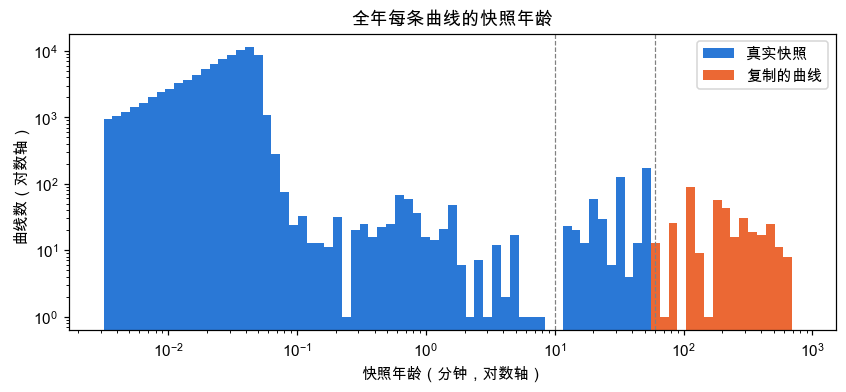

In [18]:
fig, ax = plt.subplots(figsize=(9, 3.5))
bins = np.logspace(-2.5, np.log10(curves.age_min.max() * 1.2), 80)
ax.hist(curves.age_min[~curves.is_ffill], bins=bins, color='#2a78d6', label='真实快照')
ax.hist(curves.age_min[curves.is_ffill], bins=bins, color='#eb6834', label='复制的曲线')
for edge in TIER_EDGES_MIN:
    ax.axvline(edge, color='gray', ls='--', lw=0.8)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('快照年龄（分钟，对数轴）'); ax.set_ylabel('曲线数（对数轴）')
ax.set_title('全年每条曲线的快照年龄'); ax.legend()
plt.show()

In [19]:
tier_table = pd.crosstab(curves.age_tier, curves.is_ffill.map({False: '真实快照', True: '复制'}), margins=True, margins_name='合计')
tier_table

is_ffill,复制,真实快照,合计
age_tier,,,
<10分钟,0,89403,89403
10–60分钟,0,476,476
>60分钟,366,0,366
合计,366,89879,90245


**从结果能看出什么：** 两组分得非常开：真实快照的年龄几乎都在 1–2 秒左右，复制的曲线全部超过 60 分钟。交叉表里“<10 分钟”全部是真实快照、“>60 分钟”全部是复制；中间 10–60 分钟只有 476 条曲线，都是在 bar 中途拍下的迟到快照（不是复制，但和 bar 结束时刻错开了）。

### 年龄按一天中的小时分布

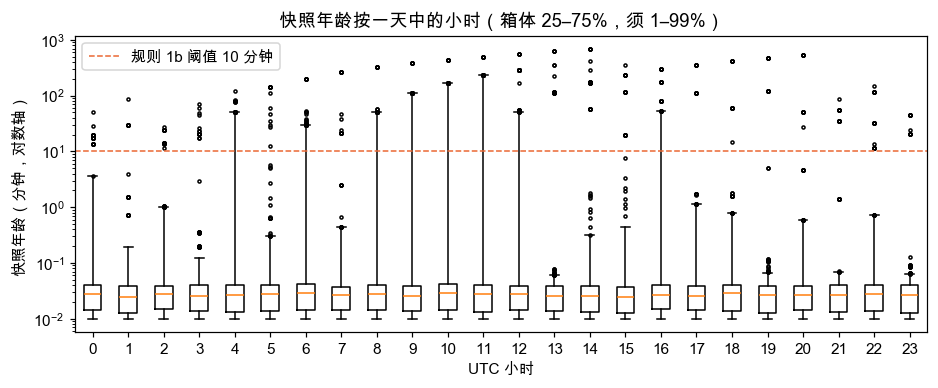

In [20]:
curves['hour_utc'] = curves.timestamp.dt.hour
age_by_hour = [curves.age_min[curves.hour_utc == h].clip(lower=0.01) for h in range(24)]
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.boxplot(age_by_hour, positions=range(24), whis=(1, 99), flierprops={'markersize': 2})
ax.axhline(rules['max_age_min'], color='#eb6834', ls='--', lw=1, label=f"规则 1b 阈值 {rules['max_age_min']} 分钟")
ax.set_yscale('log'); ax.set_xlabel('UTC 小时'); ax.set_ylabel('快照年龄（分钟，对数轴）')
ax.set_title('快照年龄按一天中的小时（箱体 25–75%，须 1–99%）'); ax.legend()
plt.show()

In [21]:
# 每个 UTC 小时中，年龄超过阈值的曲线占比
stale_share_by_hour = (curves.age_min > rules['max_age_min']).groupby(curves.hour_utc).mean()
stale_share_by_hour.sort_values(ascending=False).head(6).map('{:.2%}'.format)

hour_utc
6     2.83%
4     2.13%
9     1.49%
11    1.46%
12    1.38%
8     1.31%
Name: age_min, dtype: object

**从结果能看出什么：** 迟到快照略微集中在 UTC 凌晨到上午（占比最高的 06:00 也只有约 2.8%），其他小时都在 1.5% 以下，没有哪个小时整体不可用。

### 年龄按 tenor、按 log-moneyness 的条件分布

**log-moneyness** = ln(K/F)：0 表示平值，负数是行权价低于远期，正数是高于远期。

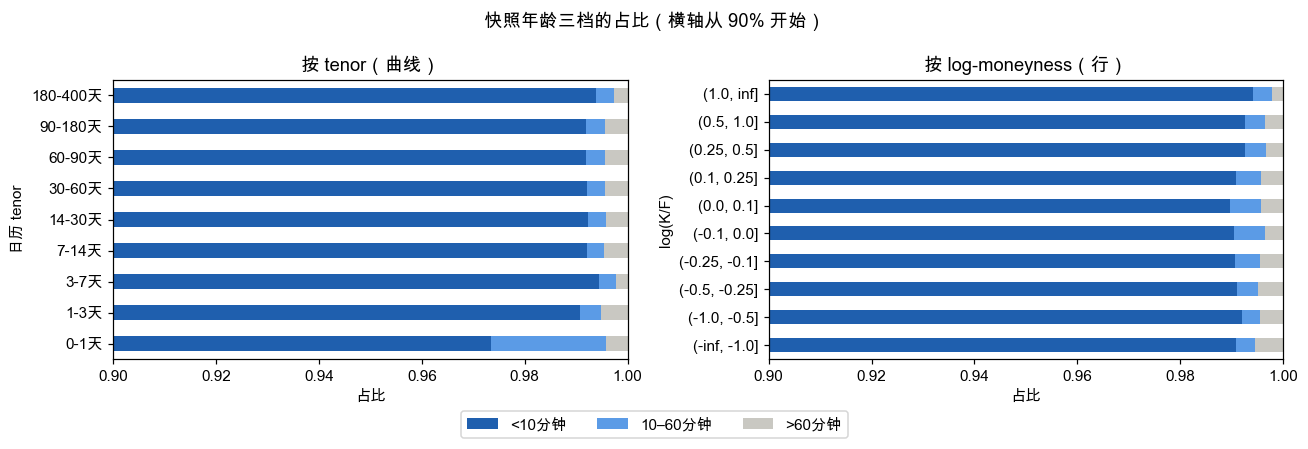

In [22]:
curves['tenor_bucket'] = tenor_bucket(curves.tenor_days)
by_tenor = pd.crosstab(curves.tenor_bucket, curves.age_tier, normalize='index')
tier_order = curves.age_tier.cat.categories
row_tier = pd.Categorical(curves.age_tier.reindex(raw.curve_id).to_numpy(), categories=tier_order)  # 每一行继承所在曲线的年龄档
by_logm = pd.crosstab(logm_bucket(raw.logm), pd.Series(row_tier, name='年龄档'), normalize='index')
by_tenor = by_tenor.reindex(columns=tier_order); by_logm = by_logm.reindex(columns=tier_order)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
by_tenor.plot.barh(stacked=True, ax=axes[0], color=['#1f5fae', '#5b9be6', '#c9c8c2'], legend=False)
by_logm.plot.barh(stacked=True, ax=axes[1], color=['#1f5fae', '#5b9be6', '#c9c8c2'], legend=False)
axes[0].set_title('按 tenor（曲线）'); axes[1].set_title('按 log-moneyness（行）')
for ax in axes:
    ax.set_xlabel('占比'); ax.set_xlim(0.9, 1.0)
axes[0].set_ylabel('日历 tenor'); axes[1].set_ylabel('log(K/F)')
fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.06))
fig.suptitle('快照年龄三档的占比（横轴从 90% 开始）'); fig.tight_layout(); plt.show()

In [23]:
fresh_label = by_tenor.columns[0]
print('各 tenor 档中 <10 分钟的占比：', by_tenor[fresh_label].map('{:.2%}'.format).to_dict())
print('各 log-moneyness 档中 <10 分钟的占比：', by_logm[fresh_label].map('{:.2%}'.format).to_dict())

各 tenor 档中 <10 分钟的占比： {'0-1天': '97.34%', '1-3天': '99.08%', '3-7天': '99.45%', '7-14天': '99.21%', '14-30天': '99.23%', '30-60天': '99.21%', '60-90天': '99.18%', '90-180天': '99.19%', '180-400天': '99.38%'}
各 log-moneyness 档中 <10 分钟的占比： {Interval(-inf, -1.0, closed='right'): '99.08%', Interval(-1.0, -0.5, closed='right'): '99.19%', Interval(-0.5, -0.25, closed='right'): '99.11%', Interval(-0.25, -0.1, closed='right'): '99.06%', Interval(-0.1, 0.0, closed='right'): '99.04%', Interval(0.0, 0.1, closed='right'): '98.97%', Interval(0.1, 0.25, closed='right'): '99.08%', Interval(0.25, 0.5, closed='right'): '99.25%', Interval(0.5, 1.0, closed='right'): '99.27%', Interval(1.0, inf, closed='right'): '99.41%'}


**从结果能看出什么：** 除了 1 天以内的曲线（<10 分钟占 97.3%），各 tenor、各 log-moneyness 档里新鲜快照的占比都在 99.0%–99.5% 之间。也就是说，复制和迟到是按“整条曲线、整个小时”发生的，不偏向特定期限或行权价，剔除它们不会让某个区域的样本变少。

### 具体例子：2025-04-24

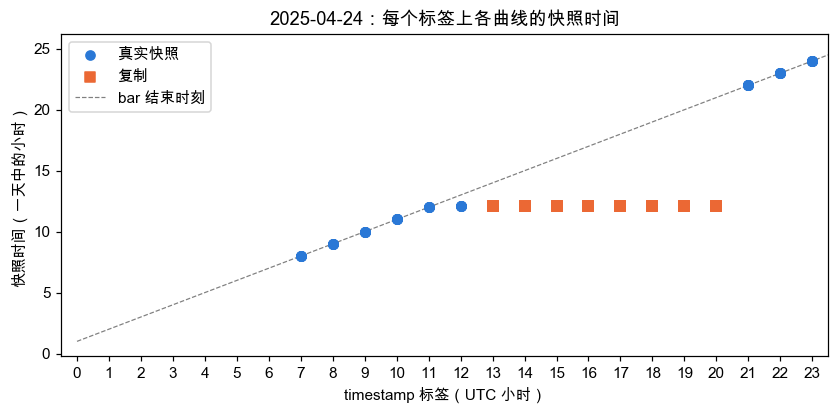

In [24]:
day = curves[curves.timestamp.dt.strftime('%Y-%m-%d') == '2025-04-24']
snap_clock = day.obs_time.dt.hour + day.obs_time.dt.minute / 60 + day.obs_time.dt.second / 3600
label_hour = day.timestamp.dt.hour
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.scatter(label_hour[~day.is_ffill], snap_clock[~day.is_ffill], color='#2a78d6', label='真实快照', zorder=3)
ax.scatter(label_hour[day.is_ffill], snap_clock[day.is_ffill], color='#eb6834', marker='s', label='复制', zorder=3)
ax.plot([0, 24], [1, 25], color='gray', lw=0.8, ls='--', label='bar 结束时刻')
ax.set_xlim(-0.5, 23.5); ax.set_xticks(range(24))
ax.set_xlabel('timestamp 标签（UTC 小时）'); ax.set_ylabel('快照时间（一天中的小时）')
ax.set_title('2025-04-24：每个标签上各曲线的快照时间'); ax.legend(); plt.show()

**从结果能看出什么：** 07:00–11:00 的快照都落在 bar 结束时刻那条虚线上；12:00 标签的快照是 12:05 拍的（离 bar 结束还有 55 分钟，所以被 1b 剔除）；13:00–20:00 这 8 个标签全部是同一个 12:05 快照的复制（橙色方块在同一高度）；00:00–06:00 没有数据；21:00 恢复正常。

### 真实的复制 vs 管道的 is_stale 标记（按行计数）

In [25]:
row_is_ffill = curves.is_ffill.reindex(raw.curve_id).to_numpy()
ffill_vs_stale = pd.crosstab(pd.Series(row_is_ffill, name='是复制的曲线'), raw.is_stale.rename('is_stale'), margins=True)
ffill_vs_stale

is_stale,False,True,All
是复制的曲线,,,
False,6076916,2462,6079378
True,12556,11490,24046
All,6089472,13952,6103424


**从结果能看出什么：** 复制的 24,046 行里，有 12,556 行（52%）没有被 is_stale 标记——这些行价格非空，看起来完全正常；另一方面，真实曲线里又有 2,462 行被标成 stale（主要是第 3 节的残留旧行）。所以 is_stale 既有漏标，又不是按曲线标的，不能代替“快照时间是否与上一次相同”的判断。

### 规则

- **1a（删除）**：删除所有复制的曲线（不论 `is_stale` 是否标记）。它们不是新的观测，只是旧快照换了一个标签。
- **1b（只标记）**：年龄超过 `rules.max_age_min` 分钟的曲线加上 `flag_late_snapshot`，**不删除**。
  它们是真实的快照，只是拍摄时刻不在 bar 结束处（例如 12:05 拍、标在 12:00），和标的 close 错开了大半个小时。
  10 分钟这个阈值远离正常快照的几秒，也远离迟到快照常见的几十分钟，结果对它不敏感（见上面的直方图）。
  默认研究过滤会排除这些曲线，但这是研究阶段的选择，不是面板的删除。

In [26]:
print('1b 阈值（分钟）：', rules['max_age_min'])
keep_1a = ~row_is_ffill
late_curves = ~curves.is_ffill & ~(curves.age_min * 60 <= rules['max_age_min'] * 60)
print(f'1b 标记的曲线：{int(late_curves.sum())} 条')

1b 阈值（分钟）： 10
1b 标记的曲线：476 条


### 删除了多少、标记了多少

In [27]:
def step_summary(keep_before, keep_after):
    rows_removed = int(keep_before.sum() - keep_after.sum())
    curves_removed = raw.curve_id[keep_before].nunique() - raw.curve_id[keep_after].nunique()
    return {'rows_in': int(keep_before.sum()), 'rows_removed': rows_removed,
            'curves_in': raw.curve_id[keep_before].nunique(), 'curves_removed': curves_removed}

all_rows = np.ones(len(raw), dtype=bool)
mine = {'1a': step_summary(all_rows, keep_1a)}   # 删除规则
mine_flags = {'1b': int(late_curves.sum())}      # 标记规则：被标记的曲线数
pd.DataFrame(mine).T

,rows_in,rows_removed,curves_in,curves_removed
1a,6103424,24046,90245,366


### 核对

In [28]:
for col in ['rows_in', 'rows_removed', 'curves_in', 'curves_removed']:
    assert mine['1a'][col] == ledger.loc['1a', col], (col, mine['1a'][col], ledger.loc['1a', col])
assert mine_flags['1b'] == flag_count('1b'), (mine_flags['1b'], flag_count('1b'))
print('规则 1a（删除）、1b（标记）与管道台账一致')

规则 1a（删除）、1b（标记）与管道台账一致


## 3. 混在新曲线里的旧数据点（规则 2a、2b）

**问题是什么。** 即使一条曲线是新拍的，里面也可能夹着**几个旧的数据点**。原因是管道按"合约名"做复制，
而 atm（平值）合成点的名字里带着当时的远期价格（例如 `BTC-16JUN25-105472-C`）。远期一变，名字就变，
旧名字的那一行就一直被复制下去，混在新曲线里。少数挂牌合约也有这种情况。

- **atm 行**：供应商在 strike = forward 处插入的合成点，不是真实挂牌合约，每条曲线应该只有一组 C/P。
- 后果：如果按 `surface_key_type == 'atm'` 去取平值 IV，会拿到好几行，其中有的是几个小时前的。

### 先看数据：每一行比所在曲线最新快照早多少

规则 1a 之后，比曲线最新快照更早的行：3,460（atm 行 3,450，挂牌合约 10）


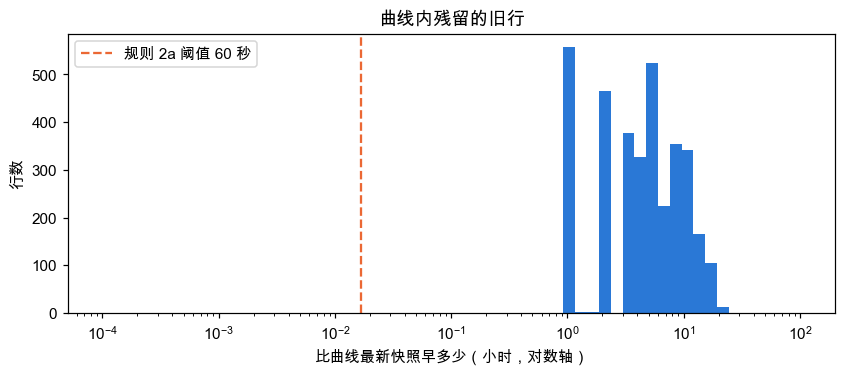

In [29]:
raw['lag_s'] = (raw.curve_obs_ms - raw.raw_timestamp) / 1000
lagged = raw[keep_1a & (raw.lag_s > 0)]
print(f'规则 1a 之后，比曲线最新快照更早的行：{len(lagged):,}（atm 行 {lagged.is_atm.sum():,}，挂牌合约 {(~lagged.is_atm).sum():,}）')
fig, ax = plt.subplots(figsize=(9, 3.3))
ax.hist(lagged.lag_s / 3600, bins=np.logspace(-4, 2, 60), color='#2a78d6')
ax.axvline(rules['lingering_tol_s'] / 3600, color='#eb6834', ls='--', label=f"规则 2a 阈值 {rules['lingering_tol_s']} 秒")
ax.set_xscale('log'); ax.set_xlabel('比曲线最新快照早多少（小时，对数轴）'); ax.set_ylabel('行数')
ax.set_title('曲线内残留的旧行'); ax.legend(); plt.show()

In [30]:
(lagged.lag_s / 3600).describe(percentiles=[0.01, 0.5, 0.99]).rename('比曲线早多少（小时）')

count    3460.000000
mean        5.608244
std         4.251921
min         0.983221
1%          0.999474
50%         4.000760
99%        17.999902
max        21.000032
Name: 比曲线早多少（小时）, dtype: float64

**从结果能看出什么：** 残留行比所在曲线的最新快照早至少约 1 小时（最小 0.98 小时、中位 4 小时、最多 21 小时），和正常行（早 0 秒）之间完全没有重叠，所以 60 秒的阈值不会误伤正常行。

In [31]:
lag_by_logm = pd.crosstab(logm_bucket(lagged.logm), lagged.is_atm.map({True: 'atm 行', False: '挂牌合约'}))
lag_by_logm['合计'] = lag_by_logm.sum(axis=1)
lag_by_logm

is_atm,atm 行,挂牌合约,合计
logm,,,
"(-0.25, -0.1]",0,2,2
"(-0.1, 0.0]",3450,6,3456
"(0.0, 0.1]",0,2,2


**从结果能看出什么：** 3,460 行残留中有 3,450 行（99.7%）是 atm 合成行，挂牌合约只有 10 行；它们几乎都在平值附近（log(K/F) 在 −0.1 到 0 之间），因为旧 atm 的行权价就是几个小时前的 forward。（比旧版多出的 8 行位于迟到的曲线里，见下文。）

### 具体例子：2025-06-14 03:00 的 16JUN25 曲线

In [32]:
example_curve = raw[(raw.timestamp == pd.Timestamp('2025-06-14 03:00', tz='UTC')) & (raw.expiry_label == '16JUN25')]
example_view = example_curve[example_curve.is_atm][['strike', 'option_type', 'raw_timestamp', 'lag_s', 'is_stale', 'forward_price']]
example_view.assign(快照时间=pd.to_datetime(example_view.raw_timestamp, unit='ms', utc=True)).drop(columns='raw_timestamp')

,strike,option_type,lag_s,is_stale,forward_price,快照时间
784712,105335.854862,call,0.000,False,105335.854862,2025-06-14 03:59:57.701000+00:00
784713,105335.854862,put,0.000,False,105335.854862,2025-06-14 03:59:57.701000+00:00
784721,105471.867410,call,3600.688,False,105471.867410,2025-06-14 02:59:57.013000+00:00
784743,105471.867410,put,3600.688,False,105471.867410,2025-06-14 02:59:57.013000+00:00


**从结果能看出什么：** 同一条曲线里有两组 atm：03:59:57 拍的那组行权价等于当前 forward（105,336），另一组是一个小时前的（行权价 105,472，早 3,601 秒），而且没有被标成 stale。如果按 surface_key_type == 'atm' 取平值 IV，就会把一小时前的值混进来。

### 规则

- **2a**：剔除比所在曲线最新快照早超过 `rules.lingering_tol_s` 秒的行。正常曲线内所有行的快照时间完全相同（相差 0 秒），
  残留的旧行至少早几十分钟，所以 60 秒的阈值不会误伤正常行。
- **2b**：atm 行只保留与曲线最新快照同时的那一组 C/P。

In [33]:
print('2a 阈值（秒）：', rules['lingering_tol_s'])
keep_2a = keep_1a & (raw.lag_s.to_numpy() <= rules['lingering_tol_s'])
atm_latest = raw.is_atm & (raw.raw_timestamp == raw.curve_obs_ms)
keep_candidate = keep_2a & (~raw.is_atm | atm_latest).to_numpy()
atm_kept = raw[keep_candidate & raw.is_atm.to_numpy()]
duplicate_atm = atm_kept.duplicated(['curve_id', 'option_type'], keep='last')
keep_2b = keep_candidate.copy()
keep_2b[duplicate_atm[duplicate_atm].index] = False

2a 阈值（秒）： 60


### 删除了多少

In [34]:
mine['2a'] = step_summary(keep_1a, keep_2a)
mine['2b'] = step_summary(keep_2a, keep_2b)
late_rows = late_curves.reindex(raw.curve_id).to_numpy()
in_late = int((keep_1a & late_rows & ~keep_2a).sum())
print(f'2a 删除的残留行中，有 {in_late} 行位于迟到（1b 标记）的曲线里')
pd.DataFrame(mine).T.loc[['2a', '2b']]

2a 删除的残留行中，有 8 行位于迟到（1b 标记）的曲线里


,rows_in,rows_removed,curves_in,curves_removed
2a,6079378,3460,89879,0
2b,6075918,0,89879,0


旧版规则 1b 先于 2a 把迟到的曲线整条删除，所以那几行残留被算在 1b 名下；现在 1b 只加标记，
它们改由 2a 删除，因此 2a 的删除数比旧版（3,452 行）多出上面这几行。2b 和曲线数不受影响。

### 核对

In [35]:
for rule in ['2a', '2b']:
    for col in ['rows_in', 'rows_removed', 'curves_in', 'curves_removed']:
        assert mine[rule][col] == ledger.loc[rule, col], (rule, col, mine[rule][col], ledger.loc[rule, col])
print('规则 2a、2b 与管道台账一致')

规则 2a、2b 与管道台账一致


## 4. 到期日和曲线质量（规则 3a、3b、3c：只标记）

**问题是什么。** 有三类曲线即使是新鲜的也可能不适合做研究：

- **离到期太近的曲线**（日历 tenor < 1 天）：只剩几个小时，IV 对时间极其敏感，拟合也常常很差。
- **拟合很差的曲线**：`r_squared`（r²）是这条曲线拟合的优度，1 表示完美，越低越差。
- **供应商自己标记有问题的曲线**：`vol_curve_check` 不是 GOOD（例如 VOL_SPIKE、BAD_SHAPE、行权价不够）。

这里的 tenor 一律用**日历时间**（到期时刻 − 快照时间），不用数据里的 `tau_years`，原因见第 7 节。

In [36]:
# 规则 2 之后的每条曲线：日历 tenor、曲线内最低 r²、是否全部 GOOD
after2 = raw[keep_2b]
c3 = after2.groupby('curve_id').agg(timestamp=('timestamp', 'first'), obs_ms=('curve_obs_ms', 'first'),
                                    expiry=('expiry', 'first'), r2_min=('r_squared', 'min'), n_rows=('strike', 'size'))
c3['flag_late'] = late_curves.reindex(c3.index).to_numpy()
obs_time = pd.to_datetime(c3.obs_ms, unit='ms', utc=True)
c3['tau_cal'] = (c3.expiry - obs_time).dt.total_seconds() / (YEAR_DAYS * 86400)
c3['tenor_days'] = c3.tau_cal * YEAR_DAYS
c3['vcc'] = after2.groupby('curve_id').vol_curve_check.agg(lambda s: s.iloc[0])

### 先看数据

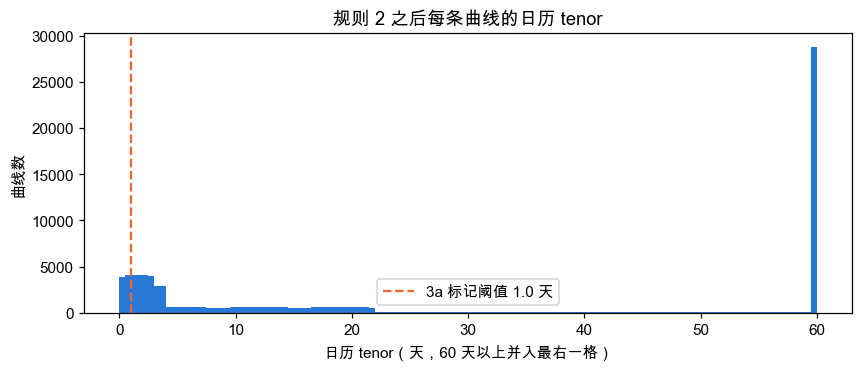

In [37]:
fig, ax = plt.subplots(figsize=(9, 3.3))
ax.hist(c3.tenor_days.clip(upper=60), bins=120, color='#2a78d6')
ax.axvline(rules['min_tenor_days'], color='#eb6834', ls='--', label=f"3a 标记阈值 {rules['min_tenor_days']} 天")
ax.set_xlabel('日历 tenor（天，60 天以上并入最右一格）'); ax.set_ylabel('曲线数')
ax.set_title('规则 2 之后每条曲线的日历 tenor'); ax.legend(); plt.show()

**从结果能看出什么：** 面板中约 8.8% 的曲线（7,928 条）离到期不到 1 天，主要是每日到期合约在最后一天的那些小时。它们现在只被标记 flag_short_tenor，默认研究过滤会排除它们。

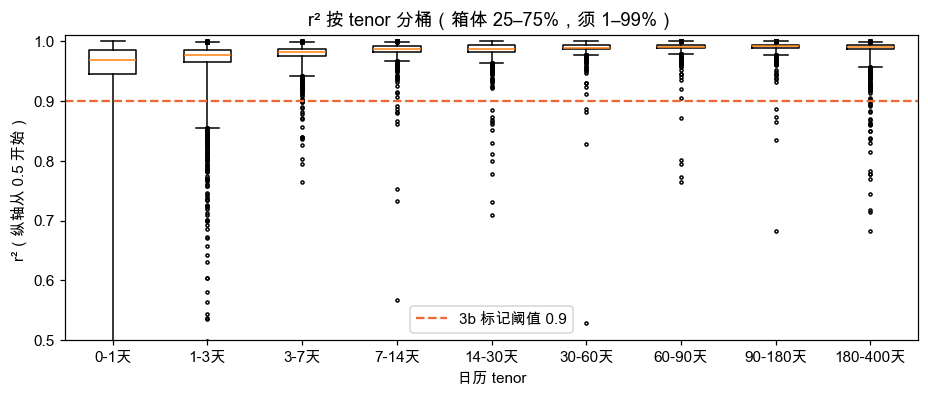

In [38]:
c3['tenor_bucket'] = tenor_bucket(c3.tenor_days)
buckets = c3.tenor_bucket.cat.categories
r2_groups = [c3.r2_min[c3.tenor_bucket == b] for b in buckets]
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.boxplot(r2_groups, tick_labels=list(buckets), whis=(1, 99), flierprops={'markersize': 2})
ax.axhline(rules['min_r_squared'], color='#eb6834', ls='--', label=f"3b 标记阈值 {rules['min_r_squared']}")
ax.set_ylim(0.5, 1.01); ax.set_xlabel('日历 tenor'); ax.set_ylabel('r²（纵轴从 0.5 开始）')
ax.set_title('r² 按 tenor 分桶（箱体 25–75%，须 1–99%）'); ax.legend(); plt.show()

In [39]:
r2_low_share = (c3.r2_min < rules['min_r_squared']).groupby(c3.tenor_bucket, observed=True).mean()
r2_low_share.map('{:.2%}'.format).rename('r² 低于阈值的比例')

tenor_bucket
0-1天        8.80%
1-3天        2.42%
3-7天        0.20%
7-14天       0.11%
14-30天      0.12%
30-60天      0.05%
60-90天      0.06%
90-180天     0.07%
180-400天    0.24%
Name: r² 低于阈值的比例, dtype: object

**从结果能看出什么：** r² 变差几乎完全集中在离到期最近的曲线上：0–1 天档有 8.8% 低于 0.9，1–3 天档 2.4%，3 天以后都不到 0.25%。这也是 3a 阈值设为 1 天、3b 设为 0.9 的依据：先标出最后一天，剩下的曲线里 0.9 只会标出明显失败的拟合。

In [40]:
vcc_counts = c3.vcc.value_counts().rename('曲线数').to_frame()
vcc_counts['占比'] = (vcc_counts['曲线数'] / len(c3)).map('{:.2%}'.format)
vcc_counts

,曲线数,占比
vcc,,
GOOD,87379,97.22%
EARLY_EXIT_INSUFFICIENT_STRIKES,1738,1.93%
IV_RV_DIFF,441,0.49%
BAD_SHAPE,128,0.14%
BAD_BASE_VAL,116,0.13%
VOL_SPIKE,62,0.07%
FAILED_PIPELINE,9,0.01%
MONEYNESS_DISCREPANCY,6,0.01%


**从结果能看出什么：** 97.2% 的曲线是 GOOD。非 GOOD 中最多的是 EARLY_EXIT_INSUFFICIENT_STRIKES（行权价不够，1.9%）和 IV_RV_DIFF（0.5%）。审计之前认为它“可能全部是 GOOD”，实际上不是；各取值的分类见下。

### 规则（全部只标记，不删除）

- **3a → `flag_short_tenor`**：日历 tenor < `rules.min_tenor_days` 天。从上面的箱线图看，r² 明显变差的正是 1 天以内的曲线；
  研究里常用的 7 天、30 天期限都远大于 1 天。
- **3b → `flag_low_r2`**：r² < `rules.min_r_squared`（r² 缺失也标记）。超过 1 天以后，绝大部分曲线的 r² 都在 0.97 以上，
  0.9 只标出明显失败的拟合。
- **3c → `vendor_check` / `vendor_check_class`**：`vol_curve_check` 的原始值，以及它在 `config/clean.yaml`
  的 `vendor_check_classes` 中的分类（GOOD / fit_quality / value_screen / ambiguous，理由见下）。出现配置里没有的取值时，管道直接报错。

标记之间互相独立、可以重叠；默认研究过滤（`research_default_filter`）决定哪些标记会排除曲线。

In [41]:
print('阈值：tenor <', rules['min_tenor_days'], '天；r² <', rules['min_r_squared'])
c3['flag_short_tenor'] = ~(c3.tenor_days >= rules['min_tenor_days'])
c3['flag_low_r2'] = ~(c3.r2_min >= rules['min_r_squared'])
c3['vendor_check'] = c3.vcc.astype(str)
class_of = {v: cls for cls, values in clean_cfg['vendor_check_classes'].items() for v in values}
c3['vendor_class'] = c3.vendor_check.map(class_of)
assert c3.vendor_class.notna().all(), '出现了配置里没有的 vol_curve_check 取值'

阈值：tenor < 1.0 天；r² < 0.9


### 标记了多少，默认研究过滤后剩多少

In [42]:
mine_flags['3a'] = int(c3.flag_short_tenor.sum())
mine_flags['3b'] = int(c3.flag_low_r2.sum())
vendor_counts = c3.vendor_check.value_counts()
pd.Series(mine_flags, name='被标记的曲线数').to_frame()

,被标记的曲线数
1b,476
3a,7928
3b,1176


In [43]:
# 独立重算默认研究过滤：按配置逐项排除
opts = clean_cfg['research_default_filter']
excluded = pd.Series(False, index=c3.index)
item_masks = {'exclude_late_snapshot': c3.flag_late, 'exclude_short_tenor': c3.flag_short_tenor,
              'exclude_low_r2': c3.flag_low_r2, 'exclude_fit_quality': c3.vendor_class == 'fit_quality',
              'exclude_value_screen': c3.vendor_class == 'value_screen', 'exclude_ambiguous': c3.vendor_class == 'ambiguous'}
for item, mask in item_masks.items():
    if opts[item]:
        excluded |= mask
n_default_mine = int((~excluded).sum())
print('配置：', opts, '| notebook 重算的默认过滤后曲线数：', n_default_mine)

配置： {'exclude_late_snapshot': True, 'exclude_short_tenor': True, 'exclude_low_r2': True, 'exclude_fit_quality': True, 'exclude_value_screen': False, 'exclude_ambiguous': False} | notebook 重算的默认过滤后曲线数： 80678


In [44]:
# 管道面板 + 研究过滤函数（研究代码以后都这样调用）
proc_curves = pd.read_parquet(PROC / 'surface_curves.parquet')
research_curves = filters.apply_research_filter(proc_curves)

apply_research_filter: 89,879 curves in
  [on ] exclude_late_snapshot  flags     476  removes     476
  [on ] exclude_short_tenor    flags   7,928  removes   7,750
  [on ] exclude_low_r2         flags   1,176  removes     462
  [on ] exclude_fit_quality    flags   1,753  removes     513
  [off] exclude_value_screen   flags     619  removes       0
  [off] exclude_ambiguous      flags     128  removes       0
  -> 80,678 curves kept


### 核对

In [45]:
assert mine_flags['3a'] == flag_count('3a') and mine_flags['3b'] == flag_count('3b')
for value in class_of:
    if value != 'GOOD':
        assert int(vendor_counts.get(value, 0)) == flag_count(f'3c_vendor_check={value}'), value
assert len(c3) == len(proc_curves) and n_default_mine == len(research_curves)
report_default = int(re.search(r'默认过滤后：\*\*(\d+)\*\*', report_md).group(1))
assert n_default_mine == report_default, (n_default_mine, report_default)
print(f'3a、3b、3c 的标记数与台账一致；默认过滤后 {n_default_mine:,} 条曲线，与 apply_research_filter() 和 clean_report.md 一致')

3a、3b、3c 的标记数与台账一致；默认过滤后 80,678 条曲线，与 apply_research_filter() 和 clean_report.md 一致


### vol_curve_check 的分类与理由

`vol_curve_check` 是供应商自己的曲线检查。各取值的含义只能从名字和曲线形状推断，所以分成三类，分别对待：

| 分类 | 取值 | 理由 | 默认过滤 |
|---|---|---|---|
| **fit_quality**（拟合质量问题） | EARLY_EXIT_INSUFFICIENT_STRIKES、FAILED_PIPELINE、MONEYNESS_DISCREPANCY | 按输入覆盖或流程失败判断，不是按 IV 的数值；后两种 smile 明显异常（平的、折线、锯齿），且全部在 1 天以内 | 排除 |
| **value_screen**（对数值的筛选） | IV_RV_DIFF、BAD_BASE_VAL、VOL_SPIKE | 按 IV 的**数值**筛选——与 RV 的差距、与基准水平的差距、相对自身历史的跳升。删掉它们会截掉 VRP 的尾部 | **保留** |
| **ambiguous**（两种情况都有） | BAD_SHAPE | 形状检查：既有翼部被截平的失败拟合，也有可能是真实跳升的曲线 | 保留（研究时把排除它作为敏感性检验） |

几个具体的观察（下面的统计和 smile 图）：

- **IV_RV_DIFF** 集中在 2025-06-30 至 07-09 的远期限曲线（27MAR26、26DEC25），紧跟在 06-28 的 tau 时钟切换之后，
  **可能是切换本身造成的**（供应商用新时钟的 IV 与按旧口径的 RV 比较）；它们的 smile 与前后的 GOOD 曲线重合。
- **BAD_BASE_VAL** 出现在 **2025-10-10、10-11** 的暴跌中，smile 与相邻 GOOD 曲线重合；删掉会截掉极端行情。
- **BAD_SHAPE** 中既有翼部被截平在一个常数上的情况，也有 **2026-02-05**（13FEB26）那种整体比相邻曲线高 20–30 个点、
  可能是真实跳升的情况。

In [46]:
class_table = pd.DataFrame({'分类': pd.Series(class_of), '面板曲线数': vendor_counts}).fillna(0)
class_table['默认过滤后保留'] = research_curves.vendor_check.value_counts().reindex(class_table.index).fillna(0)
class_table[['面板曲线数', '默认过滤后保留']] = class_table[['面板曲线数', '默认过滤后保留']].astype(int)
class_table.sort_values(['分类', '面板曲线数'], ascending=[True, False])

,分类,面板曲线数,默认过滤后保留
GOOD,GOOD,87379,80108
BAD_SHAPE,ambiguous,128,87
EARLY_EXIT_INSUFFICIENT_STRIKES,fit_quality,1738,0
FAILED_PIPELINE,fit_quality,9,0
MONEYNESS_DISCREPANCY,fit_quality,6,0
IV_RV_DIFF,value_screen,441,394
BAD_BASE_VAL,value_screen,116,82
VOL_SPIKE,value_screen,62,7


#### IV_RV_DIFF：在哪些 tenor、是否影响 7 天 / 30 天的括号到期日

In [47]:
ivrv = c3[c3.vendor_check == 'IV_RV_DIFF']
by_tenor = tenor_bucket(ivrv.tenor_days).value_counts(sort=False).rename('曲线数')
by_month = ivrv.timestamp.dt.strftime('%Y-%m').value_counts().sort_index().rename('曲线数')
print('按月份：', by_month.to_dict())
by_tenor.to_frame()

按月份： {'2025-06': 12, '2025-07': 397, '2025-09': 2, '2025-10': 9, '2025-11': 2, '2025-12': 5, '2026-01': 4, '2026-02': 6, '2026-03': 4}


,曲线数
tenor_days,
0-1天,39
1-3天,7
3-7天,1
7-14天,0
14-30天,0
30-60天,0
60-90天,13
90-180天,186
180-400天,195


In [48]:
def bracket_members(cur, target_days):
    # 每个标签上括住 target_days 的两个到期日（tenor 从 bar 结束时刻算）
    days = (cur.expiry - (cur.timestamp + HOUR)).dt.total_seconds() / 86400
    cur = cur.assign(days_label=days).sort_values('days_label')
    lower = cur[cur.days_label <= target_days].groupby('timestamp').tail(1)
    upper = cur[cur.days_label > target_days].groupby('timestamp').head(1)
    return pd.concat([lower, upper])

for target in [7, 30]:
    members = bracket_members(research_curves, target)
    hit = members[members.vendor_check == 'IV_RV_DIFF']
    print(f'括住 {target} 天：IV_RV_DIFF 是括号到期日之一的曲线 {len(hit)} 条，'
          f'涉及日期 {sorted(hit.timestamp.dt.strftime("%Y-%m-%d").unique())}')

括住 7 天：IV_RV_DIFF 是括号到期日之一的曲线 1 条，涉及日期 ['2026-02-08']
括住 30 天：IV_RV_DIFF 是括号到期日之一的曲线 0 条，涉及日期 []


#### smile 对比：每种非 GOOD 取值抽 3 条，与同一到期日相邻的 GOOD 曲线比较

In [49]:
# 只用于画形状：原始 implied_vol（同一到期日、同一时钟内比较形状，不受第 7 节时钟问题影响）
smile_rows = after2[(after2.option_type == 'call') & ~after2.is_atm][['curve_id', 'strike', 'logm', 'implied_vol']]
smile_by_curve = dict(tuple(smile_rows.sort_values(['curve_id', 'strike']).groupby('curve_id')))
c3['label'] = curves.expiry_label.reindex(c3.index).astype(str)
good_curves = c3[c3.vendor_check == 'GOOD']

In [50]:
def plot_smile(ax, curve_id, row, value):
    same = good_curves[good_curves.expiry == row.expiry]
    gap = (same.timestamp - row.timestamp).abs()
    near = same[gap <= pd.Timedelta('3h')]
    if near.empty:   # 整个到期日连续被标记时，取时间上最近的 3 条 GOOD 曲线
        near = same.loc[gap.nsmallest(3).index]
    for nid in near.index:
        p = smile_by_curve.get(nid)
        if p is not None:
            ax.plot(p.logm, p.implied_vol * 100, color='#9bbbe0', lw=1)
    p = smile_by_curve[curve_id]
    ax.plot(p.logm, p.implied_vol * 100, 'o-', color='#eb6834', ms=3, label=value)
    ax.set_title(f'{row.label} @ {row.timestamp:%Y-%m-%d %H:%M}\n日历 tenor {row.tenor_days:.1f} 天，r² {row.r2_min:.3f}', fontsize=9)
    ax.set_xlabel('log(K/F)'); ax.set_ylabel('IV (%)')

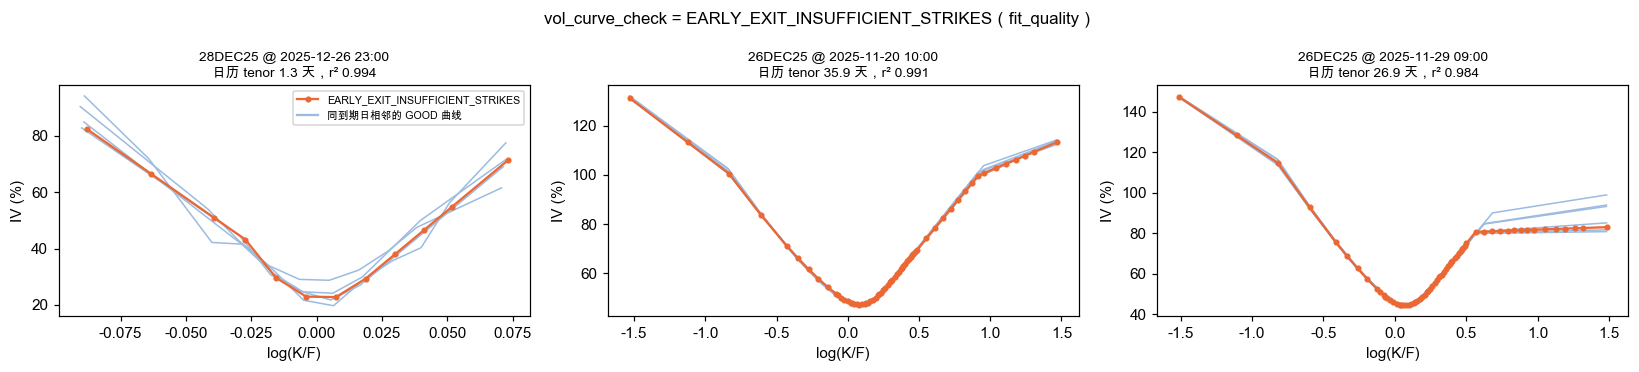

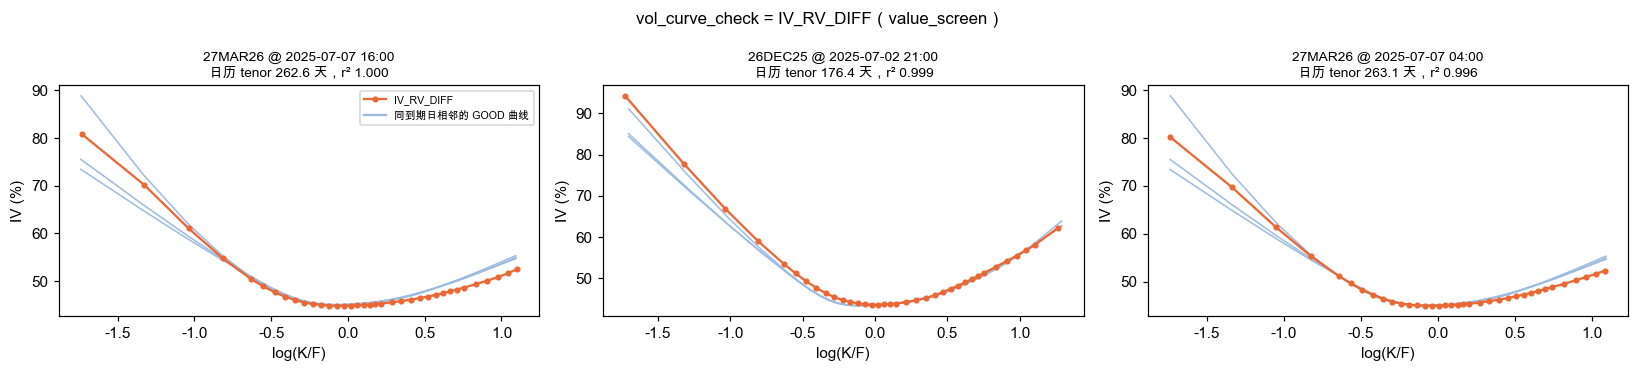

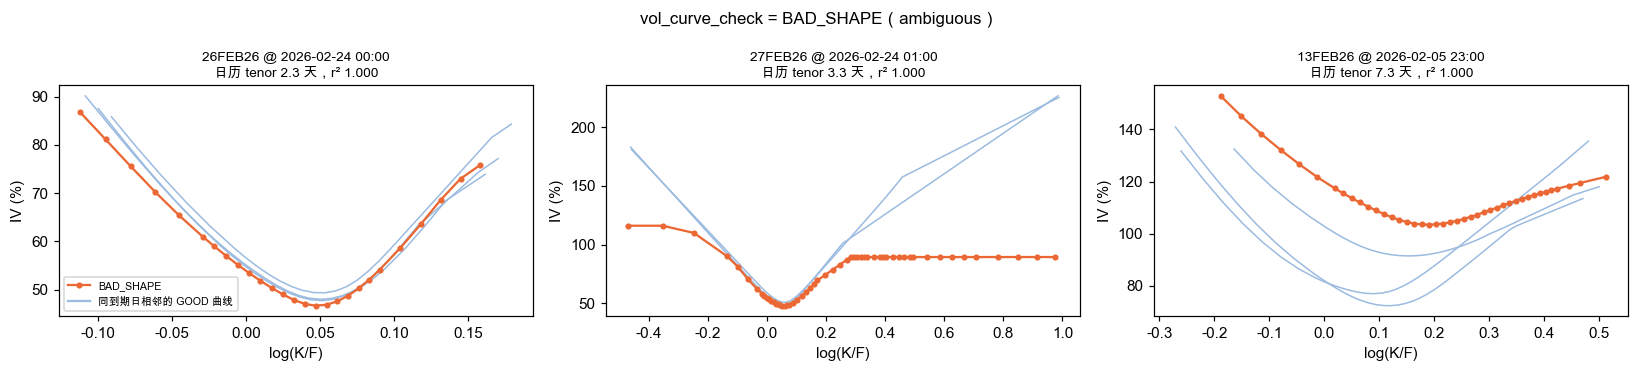

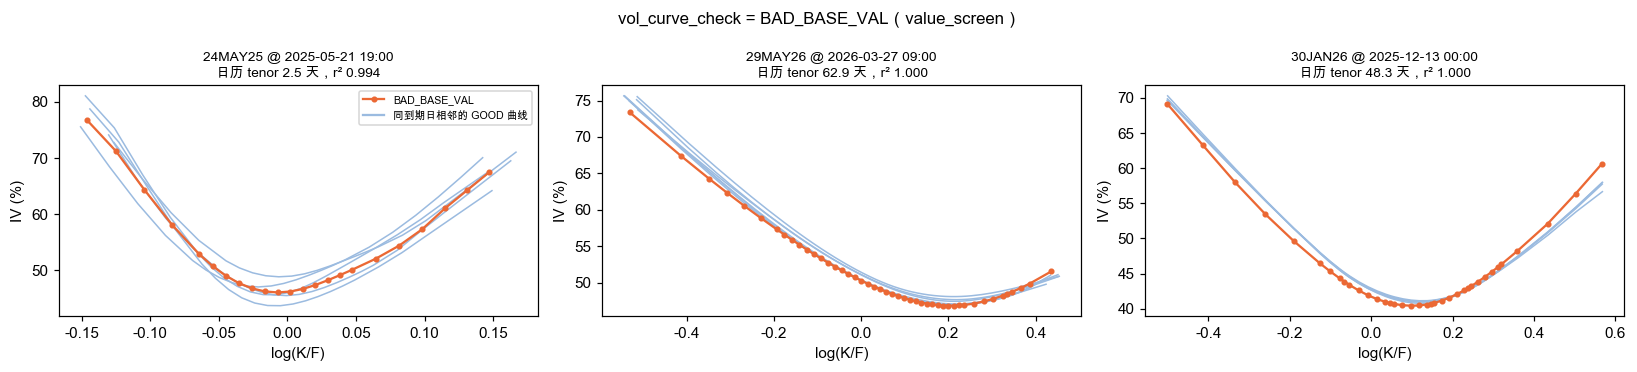

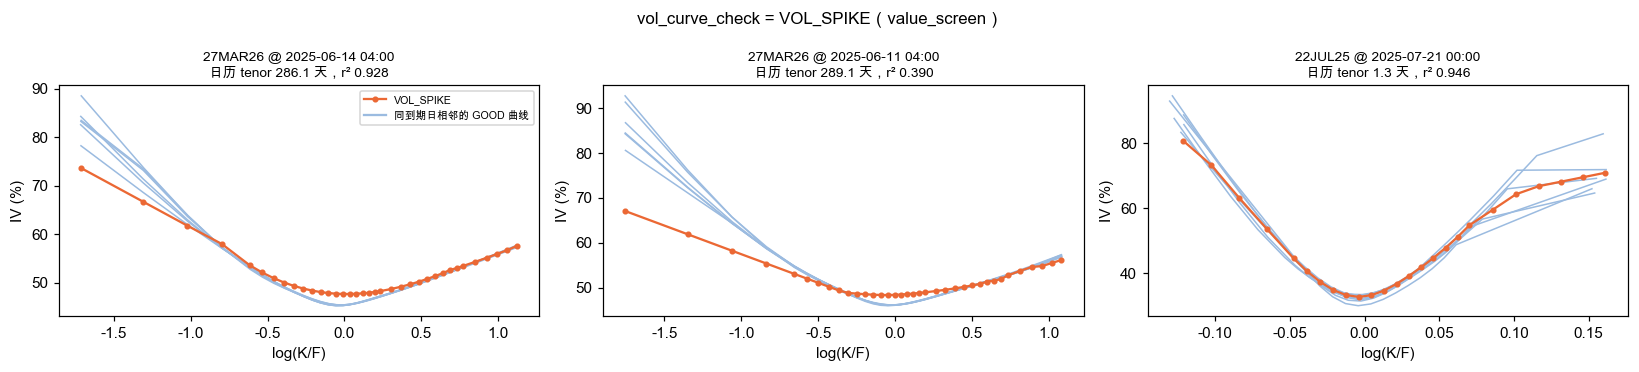

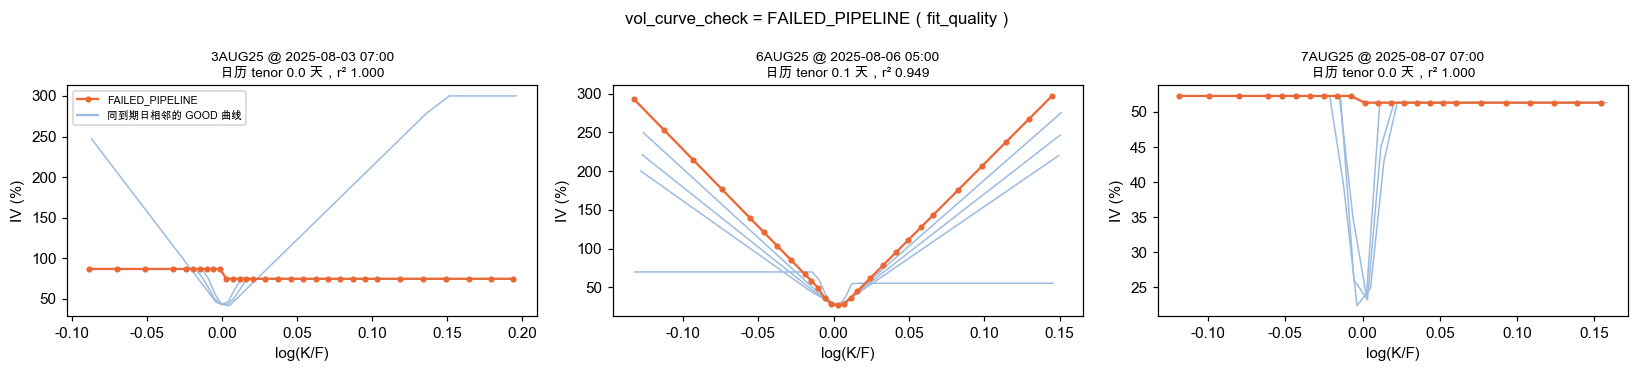

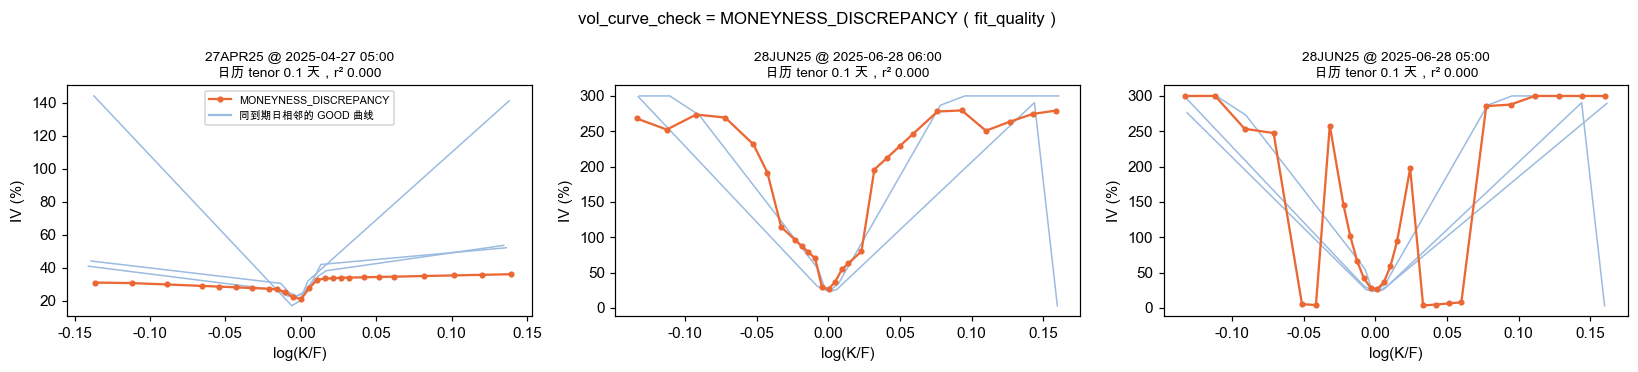

In [51]:
rng = np.random.default_rng(7)
for value in vendor_counts.index.drop('GOOD'):
    candidates = c3[(c3.vendor_check == value) & (c3.tenor_days >= 1)]
    candidates = candidates if len(candidates) >= 3 else c3[c3.vendor_check == value]
    picks = candidates.iloc[rng.choice(len(candidates), size=min(3, len(candidates)), replace=False)]
    fig, axes = plt.subplots(1, len(picks), figsize=(5 * len(picks), 3.4), squeeze=False)
    for ax, (curve_id, row) in zip(axes[0], picks.iterrows()):
        plot_smile(ax, curve_id, row, value)
    axes[0][0].plot([], [], color='#9bbbe0', label='同到期日相邻的 GOOD 曲线'); axes[0][0].legend(fontsize=7)
    fig.suptitle(f'vol_curve_check = {value}（{class_of[value]}）', fontsize=11); fig.tight_layout(); plt.show()

**从结果能看出什么：** smile 图支持上面的分类：**IV_RV_DIFF** 和 **BAD_BASE_VAL** 的曲线形状正常，与相邻（或时间上最近）的 GOOD 曲线基本重合，没有拟合失败的迹象——它们被标记的原因在于 IV 的数值，而不是曲线本身，所以归为 value_screen 并默认保留。**EARLY_EXIT_INSUFFICIENT_STRIKES** 的形状同样正常，但它说明供应商的输入覆盖不足，归为 fit_quality。**VOL_SPIKE** 的长期限例子左翼比相邻曲线低 10–25 个点（其中一条 r² 只有 0.39，已被 flag_low_r2 标出），短期限例子正常。**BAD_SHAPE** 两种情况都有：27FEB26 那条右翼被截平在 90% 左右（失败的拟合），13FEB26（2026-02-05）那条整体比相邻曲线高 20–30 个点（可能是真实跳升），因此归为 ambiguous。**FAILED_PIPELINE** 和 **MONEYNESS_DISCREPANCY** 明显异常（平的、锯齿），而且都在离到期不到 1 天的曲线上。

### 新增检查：被 3b、3c 标记的曲线，是否集中在行情剧烈的时期？

担心的是：如果行情越剧烈、拟合越容易失败，那么按 3b/3c 排除曲线就会**系统性地去掉剧烈行情时的数据**，
留下的样本偏向平静时期，后续的 VRP 研究会有偏差。现在 3b/3c 只是标记，但默认研究过滤仍会排除其中一部分
（r² 过低和 fit_quality），所以同时看两个比例。

为了衡量"行情剧烈程度"，用标的价格构造两个**诊断指标**：

- `daily_activity_sq`：当天各小时 log 收益的平方和再开方（乘以 √365.25 年化）；跨缺口的多小时收益也计入；
- `daily_activity_cc`：当天最后一个有效 close 相对前一天最后一个有效 close 的 |log 收益|。

> **这只是诊断指标，研究用的 RV 定义将在后续单独确定。** 两个指标都只在这个 notebook 里临时计算，不保存到任何文件。

- **标记比例** `flag_share`：当天未被 1b、3a 标记的曲线中，被 3b 或 3c（任何非 GOOD）标记的比例——与旧版的"剔除比例"口径相同；
- **默认排除比例** `default_excl_share`：同一批曲线中，被默认研究过滤排除的比例（r² 过低或 fit_quality）。

In [52]:
und = pd.read_parquet(PROC / 'underlying_hourly.parquet')
und['date'] = und.timestamp.dt.strftime('%Y-%m-%d')
activity_sq = np.sqrt((und.log_ret ** 2).groupby(und.date).sum(min_count=1)) * np.sqrt(YEAR_DAYS)
last_close = und.dropna(subset=['close']).groupby('date').close.last()
activity_cc = np.log(last_close / last_close.shift(1)).abs()
daily_activity = pd.DataFrame({'daily_activity_sq': activity_sq, 'daily_activity_cc': activity_cc})
daily_activity.describe().T

,count,mean,std,min,25%,50%,75%,max
daily_activity_sq,365.0,0.385975,0.195231,0.073377,0.245709,0.352445,0.479160,1.271249
daily_activity_cc,364.0,0.016081,0.016736,0.000013,0.005051,0.011870,0.021974,0.151113


In [53]:
base = c3[~c3.flag_late & ~c3.flag_short_tenor].copy()
base['date'] = base.timestamp.dt.strftime('%Y-%m-%d')
base['flagged_3bc'] = base.flag_low_r2 | (base.vendor_check != 'GOOD')
base['excluded_default'] = base.flag_low_r2 | (base.vendor_class == 'fit_quality')
shares = base.groupby('date')[['flagged_3bc', 'excluded_default']].mean()
shares.columns = ['flag_share', 'default_excl_share']
daily = daily_activity.join(shares, how='inner').dropna()
print(f'参与比较的天数：{len(daily)}；标记比例均值 {daily.flag_share.mean():.2%}（最大 {daily.flag_share.max():.2%}），'
      f'默认排除比例均值 {daily.default_excl_share.mean():.2%}（最大 {daily.default_excl_share.max():.2%}）')

参与比较的天数：342；标记比例均值 1.92%（最大 25.87%），默认排除比例均值 1.16%（最大 25.87%）


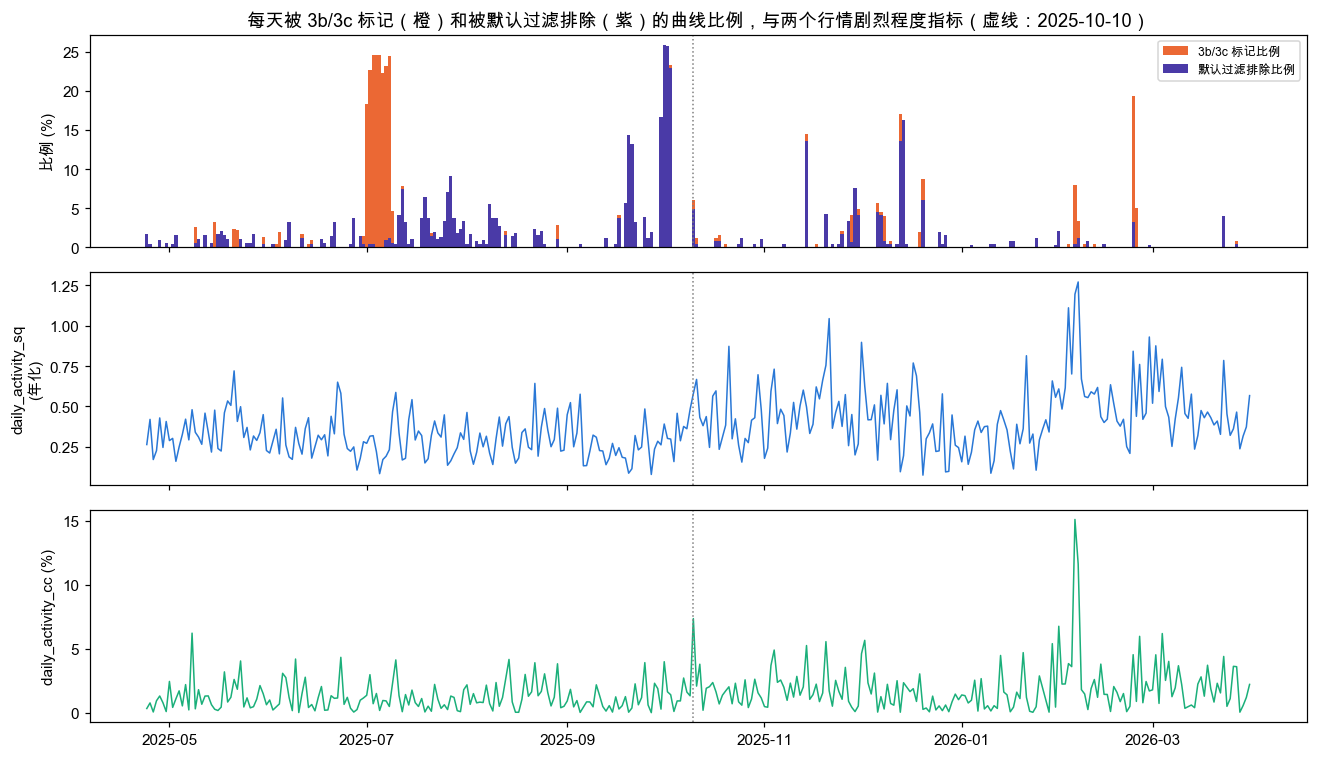

In [54]:
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
x = pd.to_datetime(daily.index)
axes[0].bar(x, daily.flag_share * 100, color='#eb6834', width=1, label='3b/3c 标记比例')
axes[0].bar(x, daily.default_excl_share * 100, color='#4a3aa7', width=1, label='默认过滤排除比例')
axes[0].set_ylabel('比例 (%)'); axes[0].legend(fontsize=8)
axes[1].plot(x, daily.daily_activity_sq, color='#2a78d6', lw=1)
axes[1].set_ylabel('daily_activity_sq\n(年化)')
axes[2].plot(x, daily.daily_activity_cc * 100, color='#1baf7a', lw=1)
axes[2].set_ylabel('daily_activity_cc (%)')
for ax in axes:
    ax.axvline(pd.Timestamp('2025-10-10'), color='gray', ls=':', lw=1)
axes[0].set_title('每天被 3b/3c 标记（橙）和被默认过滤排除（紫）的曲线比例，与两个行情剧烈程度指标（虚线：2025-10-10）')
fig.tight_layout(); plt.show()

In [55]:
corr_rows = []
for share in ['flag_share', 'default_excl_share']:
    for name in ['daily_activity_sq', 'daily_activity_cc']:
        p_r, p_p = pearsonr(daily[name], daily[share])
        s_r, s_p = spearmanr(daily[name], daily[share])
        corr_rows.append({'比例': share, '指标': name, 'Pearson r': p_r, 'Pearson p': p_p, 'Spearman ρ': s_r, 'Spearman p': s_p})
correlations = pd.DataFrame(corr_rows).set_index(['比例', '指标'])
correlations.round(4)

Pearson r  Pearson p  Spearman ρ  Spearman p
比例                 指标                                                             
flag_share         daily_activity_sq    -0.1478     0.0062     -0.1859      0.0006
                   daily_activity_cc     0.0334     0.5378     -0.1116      0.0391
default_excl_share daily_activity_sq    -0.1630     0.0025     -0.2154      0.0001
                   daily_activity_cc     0.0051     0.9250     -0.1396      0.0098

In [56]:
# 按行情剧烈程度分成五组，看每组的平均比例（%）
daily['activity_quintile'] = pd.qcut(daily.daily_activity_sq, 5, labels=['最平静', '2', '3', '4', '最剧烈'])
quintile_table = daily.groupby('activity_quintile', observed=True).agg(
    天数=('flag_share', 'size'), 平均标记比例=('flag_share', 'mean'), 平均默认排除比例=('default_excl_share', 'mean'))
quintile_table[['平均标记比例', '平均默认排除比例']] = (quintile_table[['平均标记比例', '平均默认排除比例']] * 100).round(2)
quintile_table

,天数,平均标记比例,平均默认排除比例
activity_quintile,,,
最平静,69,3.85,2.34
2,68,2.17,1.51
3,68,1.66,0.87
4,68,0.94,0.58
最剧烈,69,0.97,0.50


In [57]:
# 标记比例最高的 10 天，以及当天的行情指标排名（百分位，1 = 全年最剧烈）
top_days = daily.sort_values('flag_share', ascending=False).head(10)[['flag_share', 'default_excl_share', 'daily_activity_sq', 'daily_activity_cc']]
top_days['activity_sq_pct'] = daily.daily_activity_sq.rank(pct=True).reindex(top_days.index)
top_days.round(4)

,flag_share,default_excl_share,daily_activity_sq,daily_activity_cc,activity_sq_pct
date,,,,,
2025-10-01,0.2587,0.2587,0.3904,0.0399,0.5906
2025-10-02,0.2571,0.2571,0.3012,0.0163,0.3918
2025-07-05,0.2454,0.0000,0.0825,0.0017,0.0088
2025-07-04,0.2454,0.0000,0.2189,0.0150,0.1725
2025-07-03,0.2454,0.0046,0.3181,0.0070,0.4269
2025-07-08,0.2440,0.0119,0.2310,0.0048,0.2193
2025-10-03,0.2326,0.2292,0.2971,0.0140,0.3772
2025-07-07,0.2315,0.0093,0.1908,0.0092,0.1257
2025-07-02,0.2269,0.0046,0.3152,0.0297,0.4181


In [58]:
# 这些天被标记的曲线是什么原因、在哪些到期日
flagged_df = base[base.flagged_3bc].copy()
flagged_df['原因'] = np.where(flagged_df.flag_low_r2, '3b: r² 过低', '3c: ' + flagged_df.vendor_check)
flagged_df['expiry_label'] = curves.expiry_label.reindex(flagged_df.index).astype(str)
top_reasons = pd.crosstab(flagged_df.date[flagged_df.date.isin(top_days.index)], flagged_df['原因'])
top_reasons

原因,3b: r² 过低,3c: EARLY_EXIT_INSUFFICIENT_STRIKES,3c: IV_RV_DIFF,3c: VOL_SPIKE
date,,,,
2025-07-02,1,0,48,0
2025-07-03,1,0,52,0
2025-07-04,0,0,53,0
2025-07-05,0,0,52,1
2025-07-06,0,0,48,0
2025-07-07,2,0,48,0
2025-07-08,2,0,39,0
2025-10-01,0,67,0,0
2025-10-02,0,72,0,0


In [59]:
top_expiries = flagged_df[flagged_df.date.isin(top_days.index)].groupby(['原因', 'expiry_label']).size()
top_expiries.sort_values(ascending=False).head(8).rename('被标记的曲线数')

原因                                   expiry_label
3c: IV_RV_DIFF                       26DEC25         164
                                     27MAR26         163
3c: EARLY_EXIT_INSUFFICIENT_STRIKES  26JUN26          65
                                     27MAR26          65
                                     25SEP26          60
                                     26DEC25          15
3c: IV_RV_DIFF                       26SEP25          13
3b: r² 过低                            8JUL25            2
Name: 被标记的曲线数, dtype: int64

#### 2025-10-10 前后几天（逐小时）

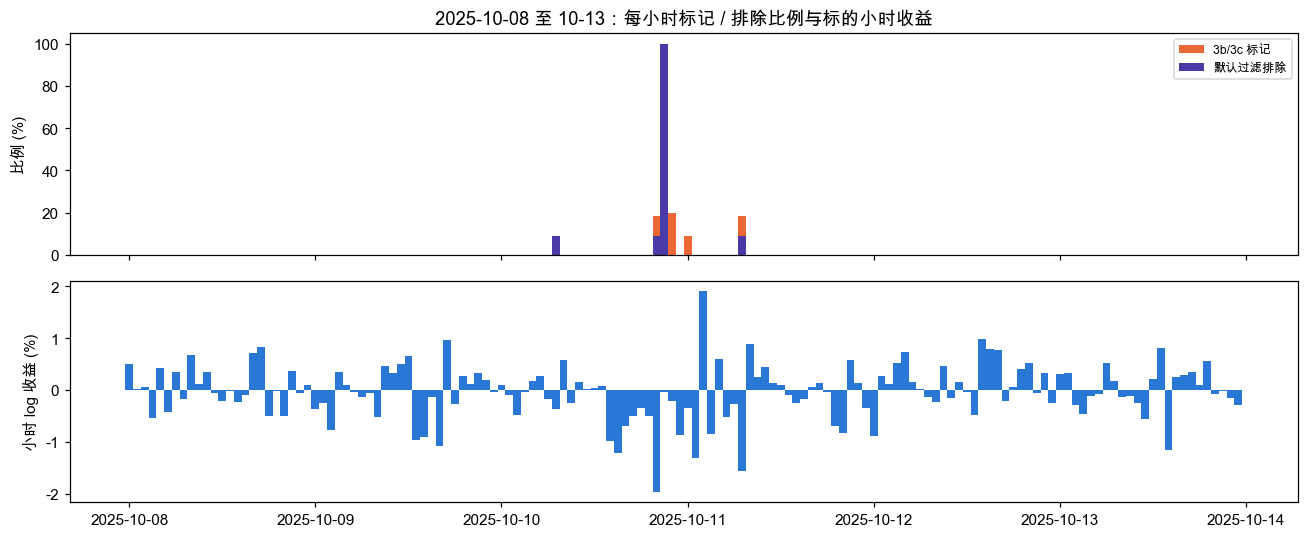

In [60]:
window = base[(base.date >= '2025-10-08') & (base.date <= '2025-10-13')]
hourly_flag = window.groupby('timestamp')[['flagged_3bc', 'excluded_default']].mean()
und_window = und[(und.date >= '2025-10-08') & (und.date <= '2025-10-13')]
fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
axes[0].bar(hourly_flag.index, hourly_flag.flagged_3bc * 100, width=1 / 24, color='#eb6834', label='3b/3c 标记')
axes[0].bar(hourly_flag.index, hourly_flag.excluded_default * 100, width=1 / 24, color='#4a3aa7', label='默认过滤排除')
axes[0].set_ylabel('比例 (%)'); axes[0].legend(fontsize=8)
axes[1].bar(und_window.timestamp, und_window.log_ret * 100, width=1 / 24, color='#2a78d6')
axes[1].set_ylabel('小时 log 收益 (%)')
axes[0].set_title('2025-10-08 至 10-13：每小时标记 / 排除比例与标的小时收益'); fig.tight_layout(); plt.show()

In [61]:
oct_days = daily.loc['2025-10-08':'2025-10-13', ['flag_share', 'default_excl_share', 'daily_activity_sq', 'daily_activity_cc']]
oct_days.round(4)

,flag_share,default_excl_share,daily_activity_sq,daily_activity_cc
date,,,,
2025-10-08,0.0000,0.0000,0.3612,0.0161
2025-10-09,0.0000,0.0000,0.4815,0.0132
2025-10-10,0.0608,0.0494,0.5784,0.0736
2025-10-11,0.0114,0.0038,0.6671,0.0208
2025-10-12,0.0000,0.0000,0.4317,0.0379
2025-10-13,0.0000,0.0000,0.3800,0.0019


In [62]:
oct_flagged = flagged_df[(flagged_df.date >= '2025-10-10') & (flagged_df.date <= '2025-10-11')]
oct_hourly = pd.crosstab(oct_flagged.timestamp, oct_flagged['原因'])
oct_hourly['当小时 log 收益 (%)'] = (und.set_index('timestamp').log_ret.reindex(oct_hourly.index) * 100).round(2)
oct_hourly

原因,3b: r² 过低,3c: BAD_BASE_VAL,3c: BAD_SHAPE,3c: EARLY_EXIT_INSUFFICIENT_STRIKES,当小时 log 收益 (%)
timestamp,,,,,
2025-10-10 07:00:00+00:00,1,0,0,0,-0.38
2025-10-10 20:00:00+00:00,1,1,0,0,-1.97
2025-10-10 21:00:00+00:00,6,0,0,5,-0.05
2025-10-10 22:00:00+00:00,0,2,0,0,-0.22
2025-10-11 00:00:00+00:00,0,1,0,0,-0.35
2025-10-11 07:00:00+00:00,1,0,1,0,-1.56


**从结果能看出什么：** **结论：被 3b/3c 标记的曲线没有集中在行情剧烈的时期；默认研究过滤排除的曲线也没有。全年层面两者与行情剧烈程度的关系都略为负向。** 标记比例（与旧版“剔除比例”口径相同，数字完全一致）：daily_activity_sq 的 Pearson r = −0.15、Spearman ρ = −0.19；daily_activity_cc 的 Pearson r = 0.03（不显著）、Spearman ρ = −0.11。默认排除比例：Pearson r = −0.16 / 0.01，Spearman ρ = −0.22 / −0.14。按行情剧烈程度分五组，最平静的一组平均标记 3.9%、默认排除 2.3%，最剧烈的一组分别只有 1.0% 和 0.5%。标记比例最高的两段日期与行情无关：2025-07-02 至 07-08 是远期限曲线（26DEC25、27MAR26）上的 IV_RV_DIFF——**改为标记之后，这一段在默认过滤下几乎不再被排除**（默认排除比例只有 0–1.2%）；2025-10-01 至 10-03 是远期限曲线上的 EARLY_EXIT_INSUFFICIENT_STRIKES（fit_quality），默认过滤仍会排除。

**局部例外仍然是 2025-10-10 的暴跌。** 当天标记比例 6.1%、默认排除 4.9%，周围几天都是 0。逐小时看：20:00 那根 −2.0% 的 K 线之后，21:00 这一小时的 11 条曲线全部被标记（6 条 r² 过低、5 条行权价不足），默认过滤会把它们全部排除；22:00 和 10-11 00:00 的 3 条 BAD_BASE_VAL 现在归为 value_screen，默认保留。所以全年统计上没有偏差，但最极端的那一个小时，曲面在默认过滤下仍然整体缺失；专门研究极端事件时，可以用 overrides 单独放开 exclude_low_r2 / exclude_fit_quality 看这几个小时。

## 5. IV 下限 0.03

**问题是什么。** 少数点的 IV 恰好等于 0.03（3%）。比特币的波动率通常在 30%–80%，3% 显然不是真实估计，
而是供应商拟合时设的**下限**（数值被"夹"在这里）。

In [63]:
pts = pd.read_parquet(PROC / 'surface_points.parquet', columns=['timestamp', 'expiry', 'strike', 'logm', 'w', 'call_delta', 'iv_floor'])
floor_pts = pts[pts.iv_floor].merge(proc_curves[KEYS + ['expiry_label', 'tenor_days_cal']], on=KEYS)
research_keys = pd.MultiIndex.from_frame(research_curves[KEYS])
floor_default = floor_pts[pd.MultiIndex.from_frame(floor_pts[KEYS]).isin(research_keys)]
print(f'面板的点：{len(pts):,}；IV 下限点：{len(floor_pts)}，涉及 {floor_pts.groupby(KEYS).ngroups} 条曲线')
print(f'默认过滤后：IV 下限点 {len(floor_default)}，涉及 {floor_default.groupby(KEYS).ngroups} 条曲线')

面板的点：2,948,112；IV 下限点：214，涉及 82 条曲线
默认过滤后：IV 下限点 42，涉及 20 条曲线


### 先看数据：下限点出现在哪里

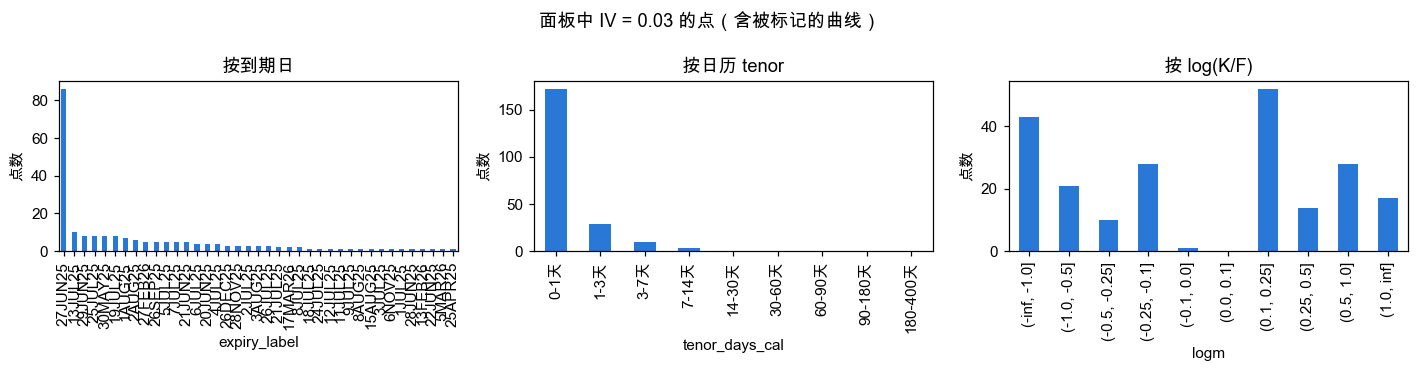

In [64]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
floor_pts.expiry_label.astype(str).value_counts().plot.bar(ax=axes[0], color='#2a78d6')
tenor_bucket(floor_pts.tenor_days_cal).value_counts(sort=False).plot.bar(ax=axes[1], color='#2a78d6')
logm_bucket(floor_pts.logm).value_counts(sort=False).plot.bar(ax=axes[2], color='#2a78d6')
axes[0].set_title('按到期日'); axes[1].set_title('按日历 tenor'); axes[2].set_title('按 log(K/F)')
for ax in axes:
    ax.set_ylabel('点数')
fig.suptitle('面板中 IV = 0.03 的点（含被标记的曲线）'); fig.tight_layout(); plt.show()

In [65]:
# 同时看原始数据（规则执行之前）里的下限点在哪些 tenor
raw_floor = raw[(raw.implied_vol - rules['iv_floor']).abs() <= rules['iv_floor_tol']]
raw_floor_tenor = tenor_bucket(curves.tenor_days.reindex(raw_floor.curve_id).to_numpy())
pd.Series(raw_floor_tenor).value_counts(sort=False).rename('原始数据中下限行数')

0-1天        344
1-3天         58
3-7天         20
7-14天         6
14-30天        0
30-60天        0
60-90天        0
90-180天       0
180-400天      0
Name: 原始数据中下限行数, dtype: int64

**从结果能看出什么：** 面板（含被标记的曲线）中有 214 个下限点、82 条曲线；默认研究过滤之后只剩 42 个点、20 条曲线（与旧版相同）。原始数据中的 428 个下限行有 80% 在离到期 1 天以内，现在它们留在面板里，但带着 flag_short_tenor，默认过滤会排除。剩下的点集中在 27JUN25 等少数到期日、日历 tenor 1.4–7.8 天，而且几乎都在深度虚值的翼部（log(K/F) 中位数约 −1.3，即行权价比 forward 低 70% 左右）。

### 规则

规则 4：**不删除，只加标记** `iv_floor`。理由：

1. 这些点很少，而且集中在远离平值的翼部，对平值 IV、常用 delta 的 IV 基本没有影响；
2. 删掉会在曲线上挖一个洞，各种插值方法会以不同方式填补，反而让不同 IV 定义之间多出一个人为差异；
3. 是否使用这些点取决于后续具体的 IV 定义（例如做 model-free 方差积分时要不要截掉翼部），所以交给后续研究决定。

### 核对

In [66]:
n_floor_points = int(pts.iv_floor.sum())
n_floor_curves = floor_pts.groupby(KEYS).ngroups
match = re.search(r'面板的点中 (\d+) 个带 `iv_floor` 标记，涉及 (\d+) 条曲线', report_md)
print('notebook：', n_floor_points, n_floor_curves, '| clean_report.md：', match.groups())
assert (n_floor_points, n_floor_curves) == (int(match.group(1)), int(match.group(2)))
assert n_floor_curves == int((proc_curves.n_iv_floor > 0).sum())

notebook： 214 82 | clean_report.md： ('214', '82')


## 6. 静态套利

**问题是什么。** 用最简单的话说：

- **蝶式套利**：同一到期日，行权价越高，看涨期权越便宜，而且"便宜下来的速度"要越来越慢（价格对行权价是凸的）。
  如果中间一个行权价的价格比两边连线还高，就能"买两边、卖中间"白赚。检查方法：相邻两段的斜率
  (C[i+1]−C[i])/(K[i+1]−K[i]) 必须越来越大（越来越接近 0）。
- **日历套利**：同一个 log-moneyness 上，到期越晚，**总方差** w = IV² × τ 必须越大。如果更远的到期日总方差反而更小，
  就意味着"负的远期方差"，同样不合理。

数据是供应商拟合出来的曲面，不是真实成交，所以这里的"套利"指的是**曲面本身的不一致**，不是能交易的机会。
价格由面板里的 w 重新计算（无折现 Black-76 只依赖 σ√T = √w）。

本节的统计基于**面板中的全部曲线**（包括被标记的曲线），与管道的 `n_butterfly_viol`、`n_calendar_viol` 口径相同。

In [67]:
def call_price_from_w(F, K, w):
    # 与清洗管道相同的公式：只依赖总方差 w
    sd = np.sqrt(np.maximum(w, 0.0))
    with np.errstate(divide='ignore', invalid='ignore'):
        d1 = (np.log(F / K) + 0.5 * w) / sd
    return np.where(sd > 0, F * norm.cdf(d1) - K * norm.cdf(d1 - sd), np.maximum(F - K, 0.0))

pts = pts.merge(proc_curves[KEYS + ['forward']], on=KEYS).sort_values(KEYS + ['strike']).reset_index(drop=True)
pts['call'] = call_price_from_w(pts.forward.to_numpy(), pts.strike.to_numpy(), pts.w.to_numpy())

In [68]:
# 蝶式：对每个中间点，右侧斜率减左侧斜率应 ≥ 0
group = pts.groupby(KEYS)
left_slope = (pts.call - group.call.shift(1)) / (pts.strike - group.strike.shift(1))
right_slope = (group.call.shift(-1) - pts.call) / (group.strike.shift(-1) - pts.strike)
pts['slope_change'] = right_slope - left_slope
pts['bfly_checked'] = pts.slope_change.notna()
pts['bfly_viol'] = pts.slope_change < -clean_cfg['flags']['butterfly_slope_tol']
print(f"蝶式：检查 {pts.bfly_checked.sum():,} 个中间点，违反 {pts.bfly_viol.sum():,}（{pts.bfly_viol.sum() / pts.bfly_checked.sum():.2%}）")

蝶式：检查 2,768,354 个中间点，违反 34,838（1.26%）


In [69]:
# 违反幅度：中间点价格比两侧连线高出多少，除以 forward
lam = (group.strike.shift(-1) - pts.strike) / (group.strike.shift(-1) - group.strike.shift(1))
chord = lam * group.call.shift(1) + (1 - lam) * group.call.shift(-1)
pts['bfly_excess'] = (pts.call - chord) / pts.forward
bfly = pts[pts.bfly_viol]
bfly.bfly_excess.describe(percentiles=[0.5, 0.9, 0.99])

count    3.483800e+04
mean     3.505583e-05
std      2.362511e-04
min      8.595900e-12
50%      1.800871e-05
90%      5.249230e-05
99%      2.211968e-04
max      2.046957e-02
Name: bfly_excess, dtype: float64

### 先看数据：违反在哪里、有多大

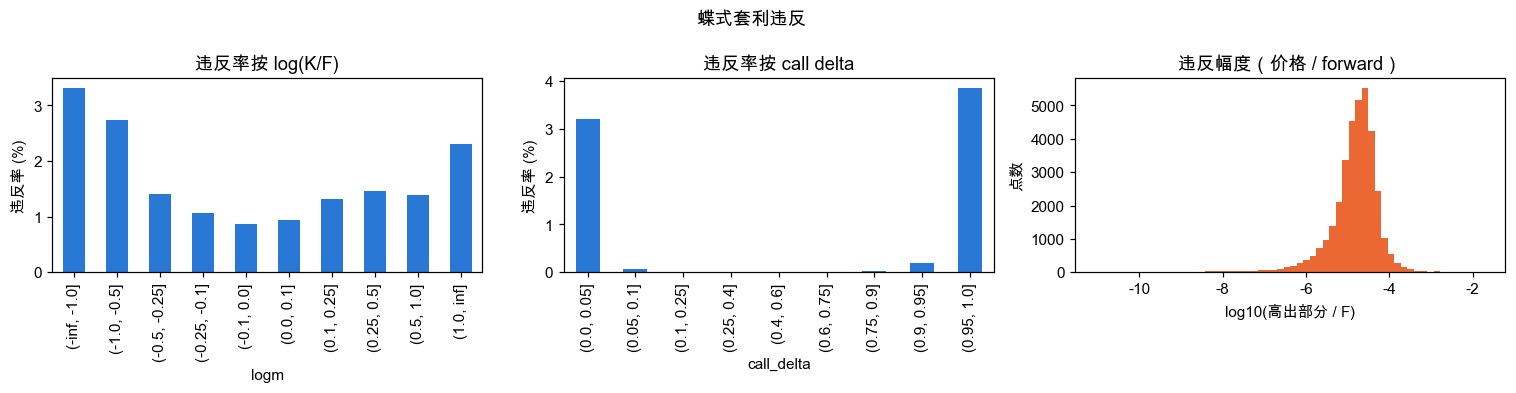

In [70]:
delta_edges = [0, 0.05, 0.1, 0.25, 0.4, 0.6, 0.75, 0.9, 0.95, 1.0]
checked = pts[pts.bfly_checked]
rate_logm = checked.bfly_viol.groupby(logm_bucket(checked.logm), observed=True).mean()
rate_delta = checked.bfly_viol.groupby(pd.cut(checked.call_delta, delta_edges), observed=True).mean()
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
(rate_logm * 100).plot.bar(ax=axes[0], color='#2a78d6'); axes[0].set_title('违反率按 log(K/F)')
(rate_delta * 100).plot.bar(ax=axes[1], color='#2a78d6'); axes[1].set_title('违反率按 call delta')
axes[2].hist(np.log10(bfly.bfly_excess), bins=60, color='#eb6834'); axes[2].set_title('违反幅度（价格 / forward）')
axes[0].set_ylabel('违反率 (%)'); axes[1].set_ylabel('违反率 (%)')
axes[2].set_xlabel('log10(高出部分 / F)'); axes[2].set_ylabel('点数')
fig.suptitle('蝶式套利违反'); fig.tight_layout(); plt.show()

In [71]:
print('违反率按 log(K/F)：', (rate_logm * 100).round(2).to_dict())
print('违反率按 call delta：', (rate_delta * 100).round(2).to_dict())

违反率按 log(K/F)： {Interval(-inf, -1.0, closed='right'): 3.32, Interval(-1.0, -0.5, closed='right'): 2.73, Interval(-0.5, -0.25, closed='right'): 1.41, Interval(-0.25, -0.1, closed='right'): 1.06, Interval(-0.1, 0.0, closed='right'): 0.87, Interval(0.0, 0.1, closed='right'): 0.93, Interval(0.1, 0.25, closed='right'): 1.31, Interval(0.25, 0.5, closed='right'): 1.47, Interval(0.5, 1.0, closed='right'): 1.38, Interval(1.0, inf, closed='right'): 2.31}
违反率按 call delta： {Interval(0.0, 0.05, closed='right'): 3.2, Interval(0.05, 0.1, closed='right'): 0.07, Interval(0.1, 0.25, closed='right'): 0.0, Interval(0.25, 0.4, closed='right'): 0.0, Interval(0.4, 0.6, closed='right'): 0.0, Interval(0.6, 0.75, closed='right'): 0.0, Interval(0.75, 0.9, closed='right'): 0.02, Interval(0.9, 0.95, closed='right'): 0.19, Interval(0.95, 1.0, closed='right'): 3.87}


**从结果能看出什么：** 在面板全部曲线上，蝶式违反占检查点的 1.26%（34,838 处——与审计时在原始真实快照上数到的数字相同，因为面板现在包含全部真实曲线），而且几乎全部在深度虚值/实值的翼部：按 call delta 看，0.05 到 0.95 之间的违反率基本为 0，违反集中在 delta < 0.05 和 > 0.95 的两端；按 log-moneyness 看，越远离平值违反率越高。违反幅度很小，中位数约为 forward 的 1.8e-5（BTC 在 10 万美元时约 2 美元）。

In [72]:
# 日历：同一标签下，每条曲线与面板中更短的那条曲线比较；在 log-moneyness 网格上插值总方差
grid_cfg = clean_cfg['flags']['calendar_k_grid']
k_grid = np.arange(grid_cfg['min'], grid_cfg['max'] + 1e-12, grid_cfg['step'])
curve_codes = pts.groupby(KEYS, sort=False).ngroup().to_numpy()
starts = np.flatnonzero(np.r_[True, curve_codes[1:] != curve_codes[:-1]])
ends = np.r_[starts[1:], len(pts)]
ts_arr, k_arr, w_arr = pts.timestamp.to_numpy(), pts.logm.to_numpy(), pts.w.to_numpy()

In [73]:
cal_counts, cal_events, prev = [], [], None
for s, e in zip(starts, ends):
    k, w = k_arr[s:e], w_arr[s:e]
    if prev is not None and prev[0] != ts_arr[s]:
        prev = None   # 换了一个时间标签，重新开始
    n_viol = 0
    if prev is not None:
        on_grid = (k_grid >= max(prev[1].min(), k.min())) & (k_grid <= min(prev[1].max(), k.max()))
        w_here, w_prev = np.interp(k_grid[on_grid], k, w), np.interp(k_grid[on_grid], prev[1], prev[2])
        bad = w_here < w_prev - clean_cfg['flags']['calendar_w_tol']
        n_viol = int(bad.sum())
        cal_events += [(kk, wp, wh) for kk, wp, wh in zip(k_grid[on_grid][bad], w_prev[bad], w_here[bad])]
    cal_counts.append(n_viol)
    prev = (ts_arr[s], k, w)

日历：违反 1,750 个网格点，涉及 1,307 条曲线


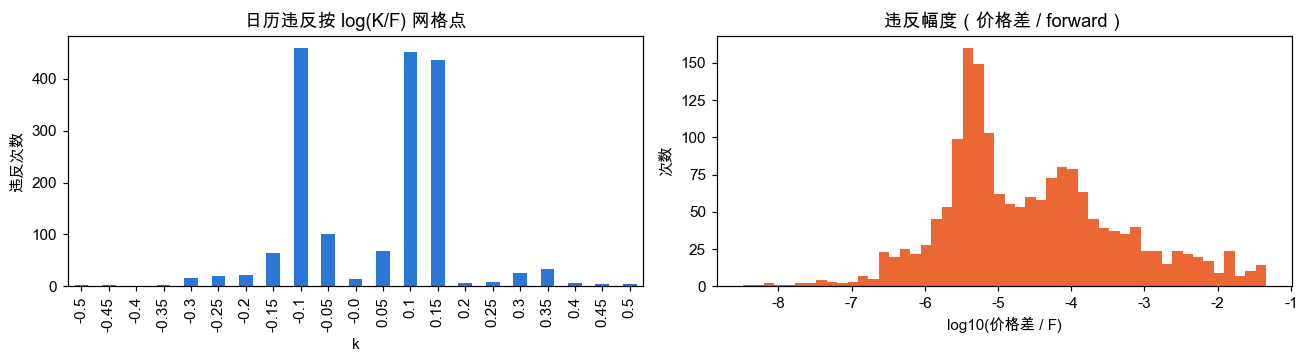

In [74]:
cal = pd.DataFrame(cal_events, columns=['k', 'w_shorter', 'w_longer'])
def call_over_forward(k, w):
    # C/F 只依赖 log-moneyness k 和总方差 w
    sd = np.sqrt(w); d1 = (-k + 0.5 * w) / sd
    return norm.cdf(d1) - np.exp(k) * norm.cdf(d1 - sd)
cal['excess'] = call_over_forward(cal.k, cal.w_shorter) - call_over_forward(cal.k, cal.w_longer)
print(f'日历：违反 {len(cal):,} 个网格点，涉及 {(np.array(cal_counts) > 0).sum():,} 条曲线')
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
cal.k.round(2).value_counts().sort_index().plot.bar(ax=axes[0], color='#2a78d6')
axes[1].hist(np.log10(cal.excess.clip(lower=1e-12)), bins=50, color='#eb6834')
axes[0].set_title('日历违反按 log(K/F) 网格点'); axes[0].set_ylabel('违反次数')
axes[1].set_title('违反幅度（价格差 / forward）'); axes[1].set_xlabel('log10(价格差 / F)'); axes[1].set_ylabel('次数')
fig.tight_layout(); plt.show()

In [75]:
print('日历违反按网格点：', cal.k.round(2).value_counts().sort_index().to_dict())
print('违反幅度（价格差 / F）分位数：', cal.excess.quantile([0.5, 0.9, 0.99]).to_dict())

日历违反按网格点： {-0.5: 2, -0.45: 3, -0.4: 1, -0.35: 2, -0.3: 17, -0.25: 20, -0.2: 21, -0.15: 64, -0.1: 460, -0.05: 100, -0.0: 14, 0.05: 68, 0.1: 452, 0.15: 437, 0.2: 6, 0.25: 9, 0.3: 26, 0.35: 33, 0.4: 7, 0.45: 4, 0.5: 4}
违反幅度（价格差 / F）分位数： {0.5: 1.647111539181817e-05, 0.9: 0.0014607434434717461, 0.99: 0.02857768403184938}


**从结果能看出什么：** 在面板全部曲线上，日历违反有 1,750 个网格点、1,307 条曲线，仍然集中在 log(K/F) = −0.1、0.1、0.15 这几个**靠近平值**的网格点上，而不是翼部；幅度中位数约为 forward 的 1.6e-5，但最大的 1% 达到 3e-2——比旧版大得多，主要来自现在保留在面板里的、离到期不到 1 天的曲线。这意味着恒定期限插值（例如 30 天 IV）在少数时刻可能得到负的远期方差，后续需要检查。

### 规则

**不删除**，只在曲线表里保留 `n_butterfly_viol` 和 `n_calendar_viol` 两个标记。理由：

1. 违反是**拟合曲面本身的性质**，几乎每个快照都有，删掉违反的曲线会损失大部分样本；
2. 违反集中在少数区域（见上图），平值附近的点基本不受影响；
3. 不同的 IV 定义受影响程度不同，应该由后续研究按定义决定怎么处理：
   - **平值 IV、固定 delta 的 IV**：只用曲线上的一个点，蝶式违反基本不影响；
   - **model-free 方差（类似 VIX 的积分）**：需要对整条曲线的价格积分，蝶式违反意味着隐含的概率密度为负，翼部违反会直接进入积分；
   - **恒定期限插值（例如 30 天 IV）**：在两个到期日之间对 w 插值，日历违反会让插值出的远期方差为负。

### 核对：每条曲线的违反数与管道一致

In [76]:
bfly_per_curve = pts.groupby(KEYS).bfly_viol.sum()
check = proc_curves.set_index(KEYS)[['n_butterfly_viol', 'n_calendar_viol']]
check['bfly_notebook'] = bfly_per_curve.reindex(check.index).fillna(0).astype(int)
cal_index = pts.iloc[starts].set_index(KEYS).index
check['cal_notebook'] = pd.Series(cal_counts, index=cal_index).reindex(check.index)
assert (check.bfly_notebook == check.n_butterfly_viol).all()
assert (check.cal_notebook == check.n_calendar_viol).all()
print('蝶式与日历违反数逐条曲线一致')

蝶式与日历违反数逐条曲线一致


In [77]:
flag_table = md_table_after(report_md, '## 质量标记（面板全部曲线）')
flag_counts = dict(zip(flag_table['标记'], flag_table['曲线数'].astype(int)))
assert flag_counts['蝶式违反 > 0（由 w 重算 call 价）'] == int((check.bfly_notebook > 0).sum())
assert flag_counts['日历违反 > 0（对比同标签下更短的面板到期日）'] == int((check.cal_notebook > 0).sum())
print('与 clean_report.md 的曲线数一致')

与 clean_report.md 的曲线数一致


### 为什么日历违反数与之前不同

日历检查比较的是**同一快照中相邻的到期日**。曲线集合变了，"相邻"关系也会变：以前被删除、现在只加标记的曲线
（例如离到期不到 1 天的曲线）插到了中间，原来相邻的两条曲线之间多了一条。蝶式检查只涉及单条曲线，不受影响。

为了让研究阶段能按任意过滤条件重新判断，管道另外输出 `surface_calendar_pairs.parquet`：同一快照内**所有**（较短, 较长）
到期日组合的违反数，`adjacent_in_panel` 标出在面板中相邻的那些。下面用它在三种曲线集合下重新确定相邻关系：
面板全部曲线、默认研究过滤后的曲线、旧版删除规则保留的曲线。

In [78]:
pairs = pd.read_parquet(PROC / 'surface_calendar_pairs.parquet')
pair_viol = pairs.set_index(['timestamp', 'expiry_short', 'expiry_long']).n_calendar_viol

def calendar_viol_under(curve_set):
    # 在给定的曲线集合中重新确定"更短的相邻到期日"，再查期限对表
    cs = curve_set.sort_values(KEYS)
    shorter = cs.groupby('timestamp').expiry.shift(1)
    keys = pd.MultiIndex.from_arrays([cs.timestamp, shorter, cs.expiry])
    counts = pair_viol.reindex(keys).fillna(0).astype(int).to_numpy()
    return pd.Series(np.where(shorter.isna(), 0, counts), index=pd.MultiIndex.from_frame(cs[KEYS]))

In [79]:
former_rules = proc_curves[~proc_curves.flag_late_snapshot & ~proc_curves.flag_short_tenor
                           & ~proc_curves.flag_low_r2 & (proc_curves.vendor_check == 'GOOD')]
viol_panel = calendar_viol_under(proc_curves)
viol_default = calendar_viol_under(research_curves)
viol_former = calendar_viol_under(former_rules)
cal_sets = pd.DataFrame({'曲线数': [len(proc_curves), len(research_curves), len(former_rules)],
                         '有日历违反的曲线': [(viol_panel > 0).sum(), (viol_default > 0).sum(), (viol_former > 0).sum()]},
                        index=['面板全部曲线', '默认研究过滤', '旧版删除规则'])
cal_sets

,曲线数,有日历违反的曲线
面板全部曲线,89879,1307
默认研究过滤,80678,617
旧版删除规则,80108,605


In [80]:
# 核对：面板口径 = 管道的 n_calendar_viol；旧版口径 = clean_report.md 中的"旧口径"
assert (viol_panel.reindex(check.index) == check.n_calendar_viol).all()
old_new = re.search(r'旧口径 (\d+) 条，现口径 (\d+) 条', report_md)
former_now = viol_panel.reindex(viol_former.index)   # 同一批旧版曲线，在面板相邻关系下
assert int((viol_former > 0).sum()) == int(old_new.group(1)) and int((former_now > 0).sum()) == int(old_new.group(2))
changed = int((viol_former != former_now).sum())
print(f'旧版也保留的 {len(former_rules):,} 条曲线中，日历违反数因相邻关系改变而变化的有 {changed} 条；'
      f'clean_report.md：旧口径 {old_new.group(1)} 条，现口径 {old_new.group(2)} 条')

旧版也保留的 80,108 条曲线中，日历违反数因相邻关系改变而变化的有 582 条；clean_report.md：旧口径 605 条，现口径 1187 条


**从结果能看出什么：** **日历违反数变化的原因完全是“相邻关系”变了，不是数据变了。** 旧版也保留的 80,108 条曲线中，有 582 条的 n_calendar_viol 变了（全部是变大）：面板里多了原先被删除的曲线（主要是 1 天以内的短期限曲线），它们插到中间，与相邻曲线之间的比较出现了违反。用期限对表按旧版删除规则的曲线集合重新确定相邻关系，正好回到旧版的 605 条；按默认研究过滤是 617 条，多出的 12 条中 4 条是保留下来的 value_screen 曲线本身，另外 8 条是旧版曲线因为中间插入了 value_screen / ambiguous 曲线而出现了违反。所以研究阶段用到日历标记时，应该在自己的过滤结果上用期限对表重新判断，而不是直接用面板的 n_calendar_viol。

## 7. tau 时钟

**问题是什么。** `tau_years` 是数据里给出的"距到期的时间（年）"，Black-76 价格就是用它算的。

- 在 **2025-06-28 00:00 UTC 之前**，它就是日历时间：(到期时刻 − 快照时间) / 365.25 天。
- **从那一刻起**，供应商换成了加权的"vol-time"时钟：一周总长仍是 7 天，但美盘时段走得快、周末走得慢。
  于是 `tau_years` 与日历期限之间的差，在一周之内来回摆动，最多相差一天以上。

### 先看数据：tau 与日历期限之差随时间变化

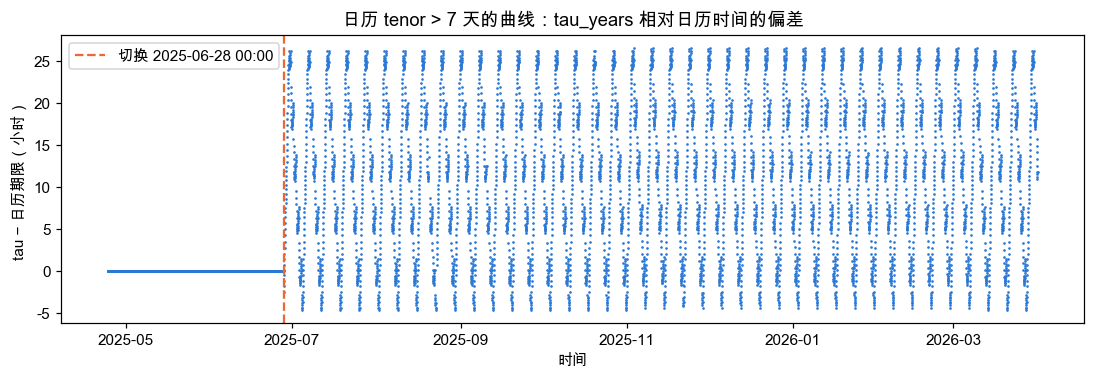

In [81]:
real_long = curves[~curves.is_ffill & (curves.tenor_days > clean_cfg['clock']['min_tenor_days'])]
offset_h = real_long.tau_years * YEAR_DAYS * 24 - real_long.tenor_days * 24
offset_by_label = offset_h.groupby(real_long.timestamp).median()
fig, ax = plt.subplots(figsize=(12, 3.4))
ax.plot(offset_by_label.index, offset_by_label.values, '.', ms=1.5, color='#2a78d6')
ax.axvline(SWITCH_TIME, color='#eb6834', ls='--', label=f'切换 {SWITCH_TIME:%Y-%m-%d %H:%M}')
ax.set_ylabel('tau − 日历期限（小时）'); ax.set_xlabel('时间')
ax.set_title(f"日历 tenor > {clean_cfg['clock']['min_tenor_days']} 天的曲线：tau_years 相对日历时间的偏差"); ax.legend()
plt.show()

**从结果能看出什么：** 2025-06-28 之前，tau_years 与日历期限的差恒为 0；之后变成每周重复一次的锯齿：差值在约 −4.7 到 +26.5 小时之间来回摆动。

### 168 小时的权重

权重 = 每个日历小时里 vol-time 走了多少小时（日历时钟下处处为 1）。美盘那一段跟随纽约时间，所以夏令时（EDT）和冬令时（EST）各一套。

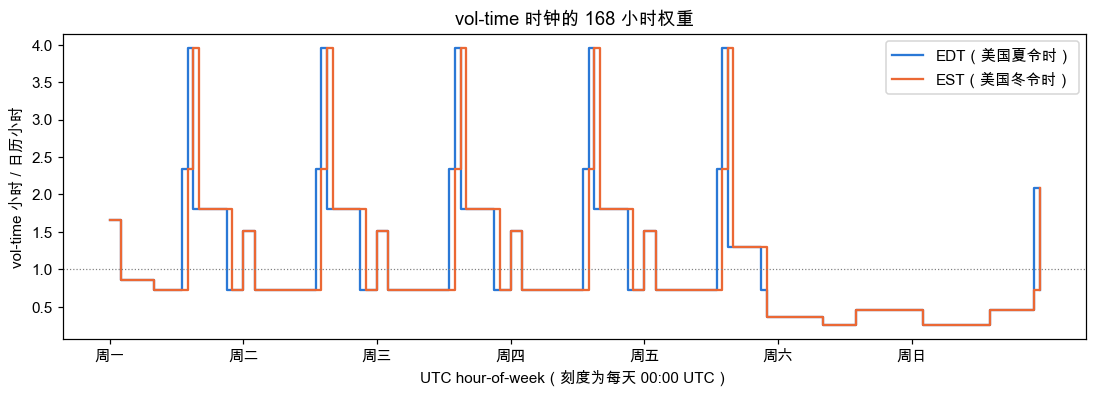

In [82]:
clock = pd.read_parquet(PROC / 'hour_of_week_clock.parquet')
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.step(clock.how, clock.weight_edt, where='post', color='#2a78d6', label='EDT（美国夏令时）')
ax.step(clock.how, clock.weight_est, where='post', color='#eb6834', label='EST（美国冬令时）')
ax.axhline(1, color='gray', lw=0.8, ls=':')
ax.set_xticks(range(0, 168, 24)); ax.set_xticklabels(['周一', '周二', '周三', '周四', '周五', '周六', '周日'])
ax.set_xlabel('UTC hour-of-week（刻度为每天 00:00 UTC）'); ax.set_ylabel('vol-time 小时 / 日历小时')
ax.set_title('vol-time 时钟的 168 小时权重'); ax.legend(); plt.show()

In [83]:
print('一周权重之和：EDT', round(clock.weight_edt.sum(), 6), '，EST', round(clock.weight_est.sum(), 6))
assert abs(clock.weight_edt.sum() - 168) < 1e-3 and abs(clock.weight_est.sum() - 168) < 1e-3

一周权重之和：EDT 167.999974 ，EST 167.999747


**从结果能看出什么：** 两条线大部分重合：亚洲时段约 0.72，美盘时段约 1.8，14:00（EDT）这一小时约 4.0，周末只有 0.26–0.46。两者的差别只在美盘那一段——EST 比 EDT 整体晚一个 UTC 小时；周日 22:00 UTC 附近的尖峰同样随夏令时移动。两套权重一周的总和都等于 168。

### 为什么不能直接用原始的 implied_vol

价格只取决于 **总方差** w = IV² × τ（Black-76 里 σ 和 T 只以 σ√T 的形式出现）。供应商给的 IV 是"按 vol-time 年化"的：
同样的 w，除以 vol-time 的 τ 得到一个 IV，除以日历 τ 得到另一个 IV。
如果直接拿原始 `implied_vol` 和按日历时间年化的已实现波动率比较，IV 会随星期几、时段系统性摆动。

所以面板里不保存 IV，只保存 **w** 和两种 τ（`tau_cal`、`tau_vol`），由后续研究**明确选择**用哪个时钟年化。
下面用一个 1–2 周期限的到期日演示两种年化的差别。

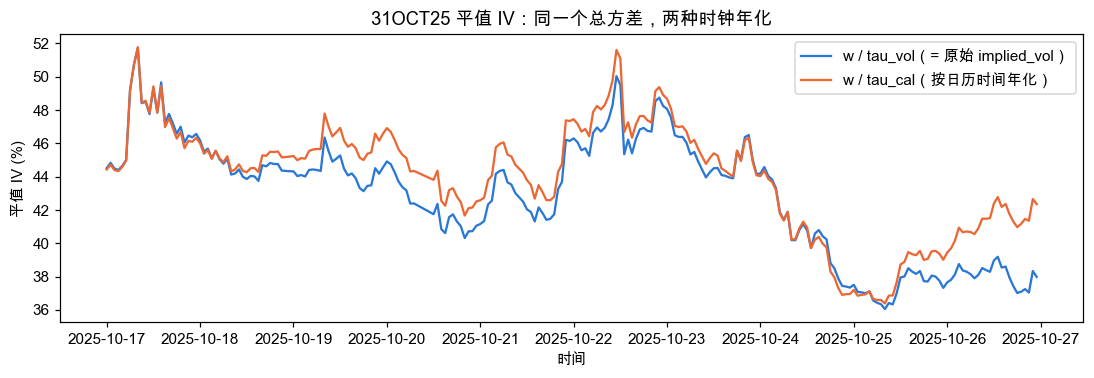

In [84]:
demo = research_curves[(research_curves.expiry_label == '31OCT25') & (research_curves.timestamp >= '2025-10-17')
                       & (research_curves.timestamp < '2025-10-27')].sort_values('timestamp')
iv_vol_clock = np.sqrt(demo.atm_w / demo.tau_vol)
iv_cal_clock = np.sqrt(demo.atm_w / demo.tau_cal)
fig, ax = plt.subplots(figsize=(12, 3.4))
ax.plot(demo.timestamp, iv_vol_clock * 100, color='#2a78d6', label='w / tau_vol（= 原始 implied_vol）')
ax.plot(demo.timestamp, iv_cal_clock * 100, color='#eb6834', label='w / tau_cal（按日历时间年化）')
ax.set_ylabel('平值 IV (%)'); ax.set_xlabel('时间')
ax.set_title('31OCT25 平值 IV：同一个总方差，两种时钟年化'); ax.legend(); plt.show()

In [85]:
ratio = iv_cal_clock / iv_vol_clock
print(f'两种年化之比 IV_cal / IV_vol：最小 {ratio.min():.3f}，最大 {ratio.max():.3f}')

两种年化之比 IV_cal / IV_vol：最小 0.985，最大 1.116


**从结果能看出什么：** 同一个总方差，用两种时钟年化，在 10-17 时几乎一样，越接近到期差距越大；到 10-26（周日）按日历年化的平值 IV 比原始 implied_vol 高约 10%（两者之比在 0.985 到 1.116 之间）。差异的大小随星期几变化，这正是不能把原始 implied_vol 直接和日历年化的 RV 比较的原因。

### calendar_anomaly 的曲线

切换之前也有少数曲线的 `tau_years` 与日历时间对不上（偏差超过 `clock.calendar_tol_s` 秒）。面板把它们标成
`calendar_anomaly`，并令 `tau_vol = tau_years`，这样任何曲线都能用 IV² = w / τ 还原原始 IV。
默认研究过滤之后剩下的是旧版的那 15 条；面板中还包含被其他标记覆盖的几条。

In [86]:
anomaly = research_curves[research_curves.clock_regime == 'calendar_anomaly']
anomaly_view = anomaly[['timestamp', 'expiry_label', 'tenor_days_cal']].copy()
anomaly_view['tau_vol − tau_cal（小时）'] = (anomaly.tau_vol - anomaly.tau_cal) * YEAR_DAYS * 24
anomaly_view

,timestamp,expiry_label,tenor_days_cal,tau_vol − tau_cal（小时）
2044,2025-05-03 14:00:00+00:00,5MAY25,1.708967,0.021656
2045,2025-05-03 14:00:00+00:00,6MAY25,2.708897,0.023343
2046,2025-05-03 14:00:00+00:00,9MAY25,5.709562,0.008617
2047,2025-05-03 14:00:00+00:00,16MAY25,12.709352,0.013651
2049,2025-05-03 14:00:00+00:00,30MAY25,26.709422,0.011974
2050,2025-05-03 14:00:00+00:00,27JUN25,54.708769,0.026419
2051,2025-05-03 14:00:00+00:00,25JUL25,82.708641,0.029496
2052,2025-05-03 14:00:00+00:00,26SEP25,145.708350,0.000384
2055,2025-05-03 15:00:00+00:00,6MAY25,2.667655,0.017593
2056,2025-05-03 15:00:00+00:00,9MAY25,5.667154,0.029627


In [87]:
regime_counts = proc_curves.clock_regime.value_counts()
flag_counts_regime = flag_counts['clock_regime = calendar_anomaly']
n_anomaly_default = int((research_curves.clock_regime == 'calendar_anomaly').sum())
print('面板：', regime_counts.to_dict(), '| clean_report.md：calendar_anomaly =', flag_counts_regime,
      '| 默认过滤后：', n_anomaly_default)
assert regime_counts['calendar_anomaly'] == flag_counts_regime
assert n_anomaly_default == len(anomaly_view)

面板： {'vol_time': 75488, 'calendar': 14276, 'calendar_anomaly': 115} | clean_report.md：calendar_anomaly = 115 | 默认过滤后： 15


**从结果能看出什么：** 面板中有 115 条 calendar_anomaly 曲线，其中 96 条同时是迟到的快照（flag_late_snapshot）、68 条离到期不到 1 天（两者可以重叠），偏差最大接近 2 小时（6,646 秒）——这些曲线在旧版里都被删除了。默认研究过滤之后剩下 15 条，正是旧版的那 15 条：全部在 2025-05-03（周六）14:00 和 15:00 两个标签上，偏差只有 1 到 137 秒。它们既不是严格的日历时钟、也不是后来的 vol-time 时钟，所以单独标出来，由后续分析决定是否排除。

### 为什么 vol-time 分析必须按 clock_regime 筛选

- 估计 168 小时权重时，只能用 `vol_time` 的曲线：切换前的 τ 是日历时间，混进来会把权重拉向 1；
- 跨越切换点的那一对相邻观测（06-27 23:00 → 06-28 00:00）τ 突然跳了一下，也不能当成一小时的 vol-time；
- `calendar_anomaly` 的曲线既不是日历时钟，也不是稳定的 vol-time 时钟，做任何时钟相关的分析都应排除。

## 8. 标的价格

**问题是什么。** 标的是永续合约 theo_mid 的小时 K 线。有四类问题：

- **缺失的小时**：某些小时根本没有数据；
- **零收益片段**：连续好几个小时 close 完全不变，几乎可以肯定是价格没更新（陈旧）；
- **open 回退**：管道用上一根 K 线的 close 当作 open，但不跨文件，所以每天 00:00 的 open 等于它自己的 close；
- **跳跃**：单小时收益远大于平时的波动。

In [88]:
UND_COLUMNS = ['timestamp', 'open', 'high', 'low', 'close']
und_range = clean_cfg['ranges']['underlyings']
und_dates = pd.date_range(und_range['start'], und_range['end']).strftime('%Y-%m-%d')
und_frames = []
for d in und_dates:
    path = RAW_UND / f'date={d}' / f'underlyings_BTC_{d}_60min.parquet'
    und_frames.append(pd.read_parquet(path, columns=UND_COLUMNS))
und_raw = pd.concat(und_frames, ignore_index=True).set_index('timestamp')
grid = pd.date_range(und_dates[0], periods=len(und_dates) * 24, freq='h', tz='UTC')
und_raw = und_raw.reindex(grid)

### 先看数据：缺失与零收益片段

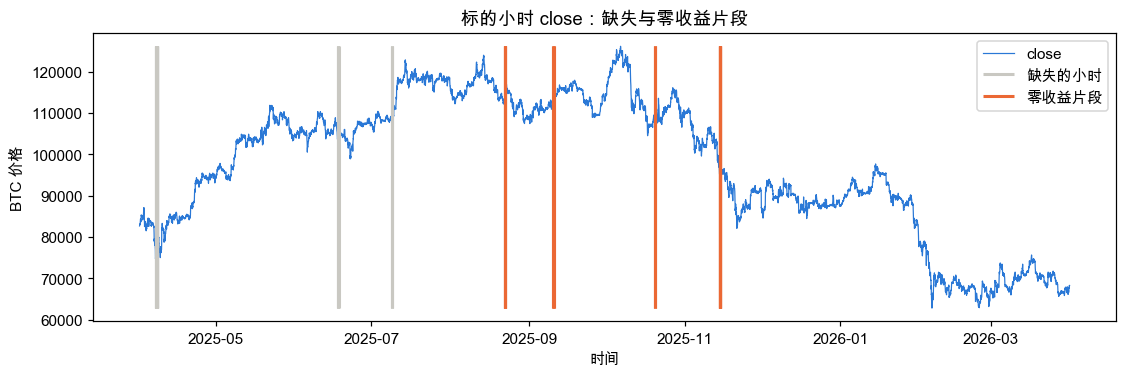

In [89]:
fig, ax = plt.subplots(figsize=(12, 3.4))
ax.plot(und_raw.index, und_raw.close, color='#2a78d6', lw=0.8, label='close')
absent = und[und.missing_reason == 'absent'].timestamp
zero_run = und[und.missing_reason == 'zero_run'].timestamp
ax.vlines(absent, und_raw.close.min(), und_raw.close.max(), color='#c9c8c2', lw=2, label='缺失的小时')
ax.vlines(zero_run, und_raw.close.min(), und_raw.close.max(), color='#eb6834', lw=2, label='零收益片段')
ax.set_ylabel('BTC 价格'); ax.set_xlabel('时间'); ax.set_title('标的小时 close：缺失与零收益片段'); ax.legend()
plt.show()

In [90]:
missing_runs = und[und.is_missing].copy()
missing_runs['run'] = (missing_runs.timestamp.diff() != HOUR).cumsum()
missing_runs.groupby('run').agg(开始=('timestamp', 'min'), 结束=('timestamp', 'max'),
                               小时数=('timestamp', 'size'), 原因=('missing_reason', 'first'))

,开始,结束,小时数,原因
run,,,,
1,2025-04-07 12:00:00+00:00,2025-04-08 00:00:00+00:00,13,absent
2,2025-06-17 23:00:00+00:00,2025-06-18 02:00:00+00:00,4,absent
3,2025-07-08 21:00:00+00:00,2025-07-08 23:00:00+00:00,3,absent
4,2025-08-22 08:00:00+00:00,2025-08-22 12:00:00+00:00,5,zero_run
5,2025-09-10 09:00:00+00:00,2025-09-10 12:00:00+00:00,4,zero_run
6,2025-10-20 09:00:00+00:00,2025-10-20 11:00:00+00:00,3,zero_run
7,2025-11-14 14:00:00+00:00,2025-11-14 21:00:00+00:00,8,zero_run


**从结果能看出什么：** 原始缺失共 20 小时，分 3 段（最长 13 小时，2025-04-07 12:00 至 04-08 00:00）；零收益片段 4 段共 20 小时（最长 8 小时，2025-11-14），被置为缺失。合计 40 小时，占全年 8,760 小时的 0.46%。

### open 回退：跨日和日内分开看

In [91]:
prev_close = und_raw.close.shift(1)
is_midnight = und_raw.index.hour == 0
has_prev = und_raw.close.notna() & prev_close.notna()
open_eq_prev = und_raw.open == prev_close
open_eq_own_close = und_raw.open == und_raw.close
open_table = pd.DataFrame({
    '跨日（00:00）': [int((has_prev & is_midnight).sum()), int((has_prev & is_midnight & ~open_eq_prev).sum()),
                     int((und_raw.close.notna() & is_midnight & open_eq_own_close).sum())],
    '日内': [int((has_prev & ~is_midnight).sum()), int((has_prev & ~is_midnight & ~open_eq_prev).sum()),
             int((und_raw.close.notna() & ~is_midnight & open_eq_own_close).sum())]},
    index=['有上一根 close 的 K 线', 'open ≠ 上一根 close', 'open = 自己的 close'])
open_table

,跨日（00:00）,日内
有上一根 close 的 K 线,361,8375
open ≠ 上一根 close,361,31
open = 自己的 close,363,2


In [92]:
# 日内 open ≠ 上一根 close 的那些 K 线：close 是否等于上一根 close（即价格陈旧）
intraday_bad = und_raw[has_prev & ~is_midnight & ~open_eq_prev]
share_flat = (intraday_bad.close == prev_close[intraday_bad.index]).mean()
print(f'日内 open ≠ 上一根 close 的 {len(intraday_bad)} 根 K 线中，close 与上一根相同的占 {share_flat:.0%}')

日内 open ≠ 上一根 close 的 31 根 K 线中，close 与上一根相同的占 100%


**从结果能看出什么：** 跨日：所有 361 根有上一根 close 的 00:00 K 线，open 都不等于前一天 23:00 的 close，而是等于自己的 close——这就是 open 回退不跨文件造成的。日内：只有 31 根 open ≠ 上一根 close，而这 31 根的 close 都和上一根完全一样，也就是价格陈旧的 K 线。结论：open 不可靠，收益一律用 close→close。

### 跳跃：两种口径并列

- **审计口径**：收益只和上一个网格小时比较；缺口之后的第一根 K 线收益是空的，所以**不可能**被识别为跳跃。
  阈值 = `underlyings.jump_k` 倍过去 `underlyings.roll_window_h` 小时的标准差（不含当根），数值见下方代码输出。
- **清洗后口径**：用清洗后的序列，跨缺口的多小时收益保留；为了与单小时收益可比，先除以 √(跨越小时数) 再比较。

> 注意：除以 √(跨越小时数) 假设缺口期间价格是"平稳地"随机游走的。如果缺口期间真的发生了一次跳跃，这个标准化会把它**稀释**，
> 所以清洗后口径可能漏掉缺口期间的真实跳跃。

In [93]:
# 审计口径：重算，并与审计输出核对
jump_k = audit_cfg['underlyings']['jump_k']
roll = audit_cfg['underlyings']['roll_window_h']
min_periods = audit_cfg['underlyings']['roll_min_periods']
print(f'跳跃阈值：{jump_k} 倍过去 {roll} 小时的标准差（至少 {min_periods} 个观测）')
ret_audit = np.log(und_raw.close / und_raw.close.shift(1))
sd_audit = ret_audit.shift(1).rolling(roll, min_periods=min_periods).std()
jumps_audit = ret_audit[(ret_audit / sd_audit).abs() > jump_k]
audit_jumps_file = pd.read_parquet(AUDIT / 'underlying_jumps.parquet')
assert set(jumps_audit.index) == set(audit_jumps_file.timestamp)
print('审计口径跳跃数：', len(jumps_audit), '（与 data/audit/underlying_jumps.parquet 一致）')

跳跃阈值：6.0 倍过去 168 小时的标准差（至少 48 个观测）
审计口径跳跃数： 14 （与 data/audit/underlying_jumps.parquet 一致）


In [94]:
# 清洗后口径：多小时收益除以 √跨越小时数，再与过去的标准差比较
valid = und.dropna(subset=['log_ret']).set_index('timestamp')
ret_scaled = valid.log_ret / np.sqrt(valid.ret_span_h)
sd_clean = ret_scaled.shift(1).rolling(roll, min_periods=min_periods).std()
z_clean = ret_scaled / sd_clean
jumps_clean = valid[z_clean.abs() > jump_k][['log_ret', 'ret_span_h']].copy()
jumps_clean['z'] = z_clean[jumps_clean.index]

In [95]:
# 标出每个跳跃是否出现在缺口或零收益片段之后的第一根 K 线
previous_reason = und.set_index('timestamp').missing_reason.shift(1)
jumps_clean['紧接在后面的'] = previous_reason.reindex(jumps_clean.index).replace({'': '-', 'absent': '缺口', 'zero_run': '零收益片段'})
jumps_clean['审计口径也识别'] = jumps_clean.index.isin(jumps_audit.index)
only_audit = jumps_audit.index.difference(jumps_clean.index)
print(f'清洗后口径 {len(jumps_clean)} 个；审计口径 {len(jumps_audit)} 个；只在审计口径中出现的：{list(only_audit.strftime("%Y-%m-%d %H:%M"))}')
jumps_clean.sort_values('z', key=abs, ascending=False)

清洗后口径 14 个；审计口径 14 个；只在审计口径中出现的：[]


,log_ret,ret_span_h,z,紧接在后面的,审计口径也识别
timestamp,,,,,
2025-08-22 14:00:00+00:00,0.029603,1.0,10.651622,-,True
2026-01-21 16:00:00+00:00,-0.030432,1.0,-8.964719,-,True
2025-07-10 21:00:00+00:00,0.025419,1.0,8.939288,-,True
2025-12-01 00:00:00+00:00,-0.038176,1.0,-8.885925,-,True
2025-07-09 19:00:00+00:00,0.020203,1.0,8.557408,-,True
2025-09-25 17:00:00+00:00,-0.019064,1.0,-8.198116,-,True
2025-10-21 14:00:00+00:00,0.034460,1.0,7.610211,-,True
2026-02-23 01:00:00+00:00,-0.035201,1.0,-7.548611,-,True
2025-04-09 17:00:00+00:00,0.049554,1.0,7.011969,-,True


In [96]:
# 7 个跨缺口的多小时收益：标准化前后的 z 值对比
multi = valid[valid.ret_span_h > 1][['log_ret', 'ret_span_h']].copy()
multi['z（除以 √跨度）'] = z_clean.reindex(multi.index)
multi['z（不标准化）'] = (multi.log_ret / sd_clean.reindex(multi.index))
multi.round(3)

,log_ret,ret_span_h,z（除以 √跨度）,z（不标准化）
timestamp,,,,
2025-04-08 01:00:00+00:00,0.044,14.0,1.804,6.750
2025-06-18 03:00:00+00:00,0.005,5.0,0.666,1.490
2025-07-09 00:00:00+00:00,0.002,4.0,0.379,0.758
2025-08-22 13:00:00+00:00,-0.005,6.0,-0.773,-1.895
2025-09-10 13:00:00+00:00,0.013,5.0,1.676,3.748
2025-10-20 12:00:00+00:00,-0.002,4.0,-0.226,-0.453
2025-11-14 22:00:00+00:00,-0.001,9.0,-0.066,-0.197


**从结果能看出什么：** **两种口径识别出的是同一组 14 个跳跃，没有一个出现在缺口或零收益片段之后的第一根 K 线上**；它们都是普通的单小时收益（跨度为 1），所以缺口处理不影响跳跃识别。7 个跨缺口的多小时收益标准化后的 |z| 都不超过 1.8。**但标准化可能稀释缺口期间真实发生的跳跃**：例如 2025-04-08 01:00 那个跨 14 小时的收益（+4.4%），除以 √14 后 z = 1.8，不标准化则 z = 6.75，会超过 6 倍的阈值。仅凭小时数据无法区分“缺口期间平稳上涨 4.4%”和“缺口期间发生了一次跳跃”，后续如果研究跳跃，应把含长缺口的窗口单独对待。

### 规则与为什么保留跨缺口的收益

规则 5：零收益片段（≥ `underlyings.zero_run_min_h` 小时）的 close 设为缺失；缺口不插值；跨缺口的收益保留为**一个多小时收益**，
并记录它跨越的小时数（`ret_span_h`）。

为什么保留：缺口期间价格确实变动了，这部分变动是真实的。如果把跨缺口的收益删掉，已实现方差会被系统性低估；
如果插值，又会凭空制造出一条不存在的价格路径（插值路径的波动比真实路径小）。保留一个多小时收益并记录跨度，
让后续的 RV 定义自己决定怎么处理（例如按跨度加权，或排除含缺口的窗口）。

### 核对

In [97]:
und_stats = md_table_after(report_md, '## 标的')
und_stats = dict(zip(und_stats['项目'], und_stats['值']))
n_missing = int(und.is_missing.sum())
n_multi = int((und.ret_span_h > 1).sum())
n_absent = int(und_raw.close.isna().sum())
print('notebook：缺失', n_missing, '原始缺失', n_absent, '多小时收益', n_multi, '| clean_report.md：', und_stats)
assert n_missing == int(und_stats['missing_hours']) and n_absent == int(und_stats['absent_hours'])
assert n_multi == int(und_stats['multi_hour_returns'])

notebook：缺失 40 原始缺失 20 多小时收益 7 | clean_report.md： {'grid_hours': '8760', 'duplicates_dropped': '0', 'absent_hours': '20', 'zero_run_hours_masked': '20', 'missing_hours': '40', 'returns': '8719', 'multi_hour_returns': '7', 'max_span_h': '14'}


## 9. 时间对齐

**问题是什么。** 期权的 timestamp 标签和标的的 timestamp 标签是否表示同一时刻？如果错开一小时，
所有"IV 对比 RV"的计算都会错位。

**检验方法**：在每个真实快照上，取期限最短（但超过 6 小时）的期权 forward F，与标的 close 在 lag = −1、0、+1 小时处比较，
看 d = log(F/close)。d 的水平主要是期货基差；更敏感的是 **d 的逐小时变化**：对齐正确时它最平稳。

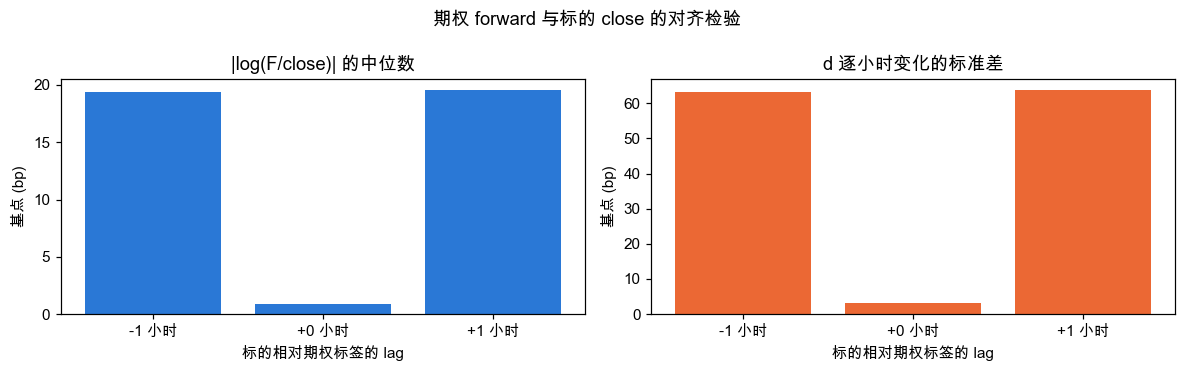

In [98]:
align_stats = pd.read_parquet(AUDIT / 'alignment_stats.parquet')
align_detail = pd.read_parquet(AUDIT / 'alignment_detail.parquet')
all_real = align_stats[align_stats.subset == 'all_real'].set_index('lag_h')
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
labels = [f'{lag:+d} 小时' for lag in all_real.index]
axes[0].bar(labels, all_real.median_abs_d * 1e4, color='#2a78d6')
axes[1].bar(labels, all_real.std_hourly_change_d * 1e4, color='#eb6834')
axes[0].set_title('|log(F/close)| 的中位数'); axes[1].set_title('d 逐小时变化的标准差')
for ax in axes:
    ax.set_ylabel('基点 (bp)'); ax.set_xlabel('标的相对期权标签的 lag')
fig.suptitle('期权 forward 与标的 close 的对齐检验'); fig.tight_layout(); plt.show()

In [99]:
# 核对：从明细重算中位数，与审计汇总一致
for lag in all_real.index:
    recomputed = align_detail[f'd_lag{lag:+d}'].abs().median()
    assert abs(recomputed - all_real.loc[lag, 'median_abs_d']) < 1e-15
all_real[['n', 'median_abs_d', 'std_hourly_change_d']]

,n,median_abs_d,std_hourly_change_d
lag_h,,,
-1,8151,0.001942,0.006333
0,8152,0.000087,0.000323
1,8150,0.001954,0.006371


**从结果能看出什么：** **结论：期权标签和标的标签对齐，lag 0 是正确的。** lag 0 时 |log(F/close)| 的中位数只有 0.9 个基点，lag ±1 时约 19.5 个基点；逐小时变化的标准差在 lag 0 时是 3.2 个基点，lag ±1 时约 63 个基点。

## 10. 汇总

### 规则瀑布表：删除

In [100]:
names = {'1a': '复制的曲线', '2a': f"比曲线早 > {rules['lingering_tol_s']} 秒的行", '2b': 'atm 只留最新一组'}
waterfall = pd.DataFrame(mine).T[['rows_in', 'rows_removed', 'curves_in', 'curves_removed']]
waterfall.insert(0, '规则', [names[r] for r in waterfall.index])
waterfall['剔除行占原始 %'] = 100 * waterfall.rows_removed / waterfall.rows_in.iloc[0]
waterfall['剔除曲线占原始 %'] = 100 * waterfall.curves_removed / waterfall.curves_in.iloc[0]
final_rows = waterfall.rows_in.iloc[-1] - waterfall.rows_removed.iloc[-1]
final_curves = waterfall.curves_in.iloc[-1] - waterfall.curves_removed.iloc[-1]
waterfall.loc['剩余'] = ['面板', final_rows, np.nan, final_curves, np.nan, np.nan, np.nan]
waterfall

,规则,rows_in,rows_removed,curves_in,curves_removed,剔除行占原始 %,剔除曲线占原始 %
1a,复制的曲线,6103424,24046.0,90245,366.0,0.393976,0.405563
2a,比曲线早 > 60 秒的行,6079378,3460.0,89879,0.0,0.056689,0.000000
2b,atm 只留最新一组,6075918,0.0,89879,0.0,0.000000,0.000000
剩余,面板,6075918,NaN,89879,NaN,NaN,NaN


In [101]:
# 核对：与 clean_report.md 的删除表逐行一致
report_rules = md_table_after(report_md, '## 规则：删除（按顺序执行）')
report_rules.index = report_rules.rule.str[:2]
for rule in mine:
    for col in ['rows_in', 'rows_removed', 'curves_in', 'curves_removed']:
        assert int(report_rules.loc[rule, col]) == mine[rule][col], (rule, col)
assert final_curves == len(proc_curves) and final_curves == ledger.curves_in.iloc[-1] - ledger.curves_removed.iloc[-1]
print(f'删除表与 clean_report.md 完全一致；面板 {final_rows:,} 行，{final_curves:,} 条曲线')

删除表与 clean_report.md 完全一致；面板 6,075,918 行，89,879 条曲线


### 规则瀑布表：标记（不删除，标记之间可能重叠）

In [102]:
flag_rows = [('1b', f"年龄 > {rules['max_age_min']} 分钟", mine_flags['1b']),
             ('3a', f"日历 tenor < {rules['min_tenor_days']} 天", mine_flags['3a']),
             ('3b', f"r² < {rules['min_r_squared']}", mine_flags['3b'])]
for value in class_of:
    if value != 'GOOD':
        flag_rows.append((f'3c_vendor_check={value}', f'{class_of[value]}', int(vendor_counts.get(value, 0))))
flag_waterfall = pd.DataFrame(flag_rows, columns=['规则', '含义', '被标记的曲线'])
flag_waterfall['占面板 %'] = 100 * flag_waterfall['被标记的曲线'] / final_curves
flag_waterfall.loc[len(flag_waterfall)] = ['默认研究过滤后', '剩余曲线', n_default_mine, 100 * n_default_mine / final_curves]
flag_waterfall

,规则,含义,被标记的曲线,占面板 %
0,1b,年龄 > 10 分钟,476,0.529601
1,3a,日历 tenor < 1.0 天,7928,8.820748
2,3b,r² < 0.9,1176,1.308426
3,3c_vendor_check=EARLY_EXIT_INSUFFICIENT_STRIKES,fit_quality,1738,1.933711
4,3c_vendor_check=FAILED_PIPELINE,fit_quality,9,0.010013
5,3c_vendor_check=MONEYNESS_DISCREPANCY,fit_quality,6,0.006676
6,3c_vendor_check=IV_RV_DIFF,value_screen,441,0.490660
7,3c_vendor_check=BAD_BASE_VAL,value_screen,116,0.129062
8,3c_vendor_check=VOL_SPIKE,value_screen,62,0.068982
9,3c_vendor_check=BAD_SHAPE,ambiguous,128,0.142414


In [103]:
# 核对：与 clean_report.md 的标记表逐行一致
report_flags = md_table_after(report_md, '## 规则：标记（不删除，标记之间可能重叠）')
report_flag_counts = dict(zip(report_flags.rule, report_flags.curves_flagged.astype(int)))
for rule_id, _, n in flag_rows:
    matching = [r for r in report_flag_counts if r.startswith(rule_id)]
    assert len(matching) == 1 and report_flag_counts[matching[0]] == n, (rule_id, n, matching)
assert n_default_mine == report_default == len(research_curves)
print(f'标记表与 clean_report.md 完全一致；默认研究过滤后 {n_default_mine:,} 条曲线')

标记表与 clean_report.md 完全一致；默认研究过滤后 80,678 条曲线


### report.json 里不可信的字段

In [104]:
xcheck = pd.read_parquet(AUDIT / 'file_report_crosscheck.parquet')
bad_fields = xcheck[~xcheck.match].groupby(['dataset', 'field']).size().rename('不一致的天数').reset_index()
reasons = {
    'expected_grid_points': '只统计当天第一个到最后一个观测之间的网格，不是完整的 24 小时',
    'missing_grid_points': '同上；当天首尾之外的缺失小时不算，所以经常报告 0',
    'missing_price_rows': '不统计被清空价格的 stale 行',
    'raw_rows': '与"非复制曲线的行数"相差几行到一百多行，定义不明',
}
bad_fields['原因'] = bad_fields.field.map(reasons)
bad_fields

,dataset,field,不一致的天数,原因
0,options,expected_grid_points,5,只统计当天第一个到最后一个观测之间的网格，不是完整的 24 小时
1,options,missing_grid_points,5,同上；当天首尾之外的缺失小时不算，所以经常报告 0
2,options,missing_price_rows,129,不统计被清空价格的 stale 行
3,options,raw_rows,195,"与""非复制曲线的行数""相差几行到一百多行，定义不明"
4,underlyings,expected_grid_points,5,只统计当天第一个到最后一个观测之间的网格，不是完整的 24 小时
5,underlyings,missing_grid_points,5,同上；当天首尾之外的缺失小时不算，所以经常报告 0


此外，以下**数据列**也不能直接信任：`is_stale`（复制后两小时内不标记）、`quote_age_ms`（= timestamp − raw_timestamp，真实快照为负）、
`tenor_days`（= tau_years × 365，不是日历天数）、`implied_vol`（切换后按 vol-time 年化）、`vol_curve_check`（审计前以为全是 GOOD，实际不是）。

### 后续研究需要记住的事项

In [105]:
# 仅用于计算样本边界，研究用的 RV 窗口尚未确定
RV_WINDOW_DAYS_FOR_BOUNDARY = 30
opt_start, opt_end = pd.Timestamp(opt_range['start'], tz='UTC'), pd.Timestamp(opt_range['end'], tz='UTC')
und_start = pd.Timestamp(und_range['start'], tz='UTC')
first_full_window = und_start + pd.Timedelta(days=RV_WINDOW_DAYS_FOR_BOUNDARY)
last_expost_start = opt_end + pd.Timedelta(days=1) - pd.Timedelta(days=RV_WINDOW_DAYS_FOR_BOUNDARY)
calendar_curves = research_curves[research_curves.clock_regime == 'calendar']   # 默认研究过滤后
vol_curves = research_curves[research_curves.clock_regime == 'vol_time']

In [106]:
notes = pd.DataFrame([
    ('期权样本区间', f'{opt_start:%Y-%m-%d} 至 {opt_end:%Y-%m-%d}'),
    ('标的样本区间', f"{und_range['start']} 至 {und_range['end']}"),
    ('日历时钟（calendar）可用区间', f'{calendar_curves.timestamp.min():%Y-%m-%d %H:%M} 至 {calendar_curves.timestamp.max():%Y-%m-%d %H:%M}'),
    ('vol-time 时钟可用区间', f'{vol_curves.timestamp.min():%Y-%m-%d %H:%M} 至 {vol_curves.timestamp.max():%Y-%m-%d %H:%M}'),
    (f'RV 预热期（{RV_WINDOW_DAYS_FOR_BOUNDARY} 天窗口，仅示意）', f'第一个完整的历史窗口结束于 {first_full_window:%Y-%m-%d}；期权前 {(first_full_window - opt_start).days} 天不足'),
    (f'ex-post VRP 终点（{RV_WINDOW_DAYS_FOR_BOUNDARY} 天窗口，仅示意）', f'最后一个有完整未来窗口的起点 {last_expost_start:%Y-%m-%d}'),
    ('年化约定', f'tau_cal 按 {YEAR_DAYS} 天/年；RV 年化统一用 {YEAR_DAYS}×24 小时/年'),
    ('vol-time 权重', '按 UTC hour-of-week，分 EDT / EST 两套；使用时按纽约是否处于夏令时选列'),
    ('研究过滤', '统一调用 clean.filters.apply_research_filter()，不另写条件；排除 ambiguous 作为敏感性检验'),
], columns=['事项', '内容'])
notes

,事项,内容
0,期权样本区间,2025-04-24 至 2026-03-31
1,标的样本区间,2025-04-01 至 2026-03-31
2,日历时钟（calendar）可用区间,2025-04-24 07:00 至 2025-06-27 23:00
3,vol-time 时钟可用区间,2025-06-28 00:00 至 2026-03-31 23:00
4,RV 预热期（30 天窗口，仅示意）,第一个完整的历史窗口结束于 2025-05-01；期权前 7 天不足
5,ex-post VRP 终点（30 天窗口，仅示意）,最后一个有完整未来窗口的起点 2026-03-02
6,年化约定,tau_cal 按 365.25 天/年；RV 年化统一用 365.25×24 小时/年
7,vol-time 权重,按 UTC hour-of-week，分 EDT / EST 两套；使用时按纽约是否处于夏令时选列
8,研究过滤,统一调用 clean.filters.apply_research_filter()，不另写...


**从结果能看出什么：** 注意：ex-post VRP 的终点是 2026-03-02（30 天窗口覆盖 03-02 至 03-31）。两种时钟各自的可用区间按默认研究过滤后的曲线计算；RV 窗口长度确定后，需要按本表重新计算样本边界。